In [1]:
# ============================================================================
# Install the 'albumentations' library (image augmentation framework).
# -q suppresses verbose output. Albumentations is used later to define
# training-time augmentations (random crop, flip, CLAHE, noise, etc.)
# that improve the model's generalization on retinal fundus images.
# ============================================================================
!pip install -q albumentations


In [2]:
# ============================================================================
# IMPORTS — All libraries used throughout the notebook
# ============================================================================

# --- Standard library & general-purpose ---
import os  # Filesystem operations (path checking, directory creation)
import random  # Python built-in random number generator (for seed_everything)
import subprocess  # Shell command execution (for unzipping dataset files)

# --- Image processing ---
import cv2  # OpenCV: used for all four preprocessing stages (Gaussian blur,

#   thresholding, unsharp masking, gamma correction, resizing)
import numpy as np  # Numerical arrays: backbone of all image manipulations
import pandas as pd  # Tabular data: reading train.csv, storing training history
import matplotlib.pyplot as plt  # Plotting: preprocessing visualization grid
from PIL import Image  # Pillow: loading preprocessed PNGs into the Dataset class

# --- Progress bar ---
from tqdm.auto import tqdm  # tqdm: shows progress bars during preprocessing & training

# --- PyTorch core ---
import torch  # The deep learning framework
import torch.nn as nn  # Neural network modules (layers, loss functions)
import torch.nn.functional as F  # Functional API (softmax, cross_entropy, pooling)
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
#   Dataset       — base class for our custom APTOSDataset
#   DataLoader    — batches & shuffles data, feeds it to the GPU
#   WeightedRandomSampler — oversamples minority classes to combat class imbalance

# --- timm (PyTorch Image Models) ---
import timm  # Provides 1000+ pretrained vision models; we use Swin Transformer Base
# ("swin_base_patch4_window12_384.ms_in22k") with ImageNet-22K pretraining

# --- Albumentations (image augmentation) ---
import albumentations as A  # Augmentation pipeline builder
from albumentations.pytorch import ToTensorV2  # Converts numpy images → PyTorch tensors

# --- Scikit-learn (evaluation & splitting) ---
from sklearn.model_selection import train_test_split  # Stratified train/val split
from sklearn.utils.class_weight import compute_class_weight  # Computes balanced weights
from sklearn.metrics import (
    accuracy_score,
    cohen_kappa_score,
    classification_report,
    precision_recall_fscore_support,
)
#   accuracy_score           — overall % correct
#   cohen_kappa_score        — Quadratic Weighted Kappa (QWK): the PRIMARY metric for
#                              ordinal DR grading (penalizes predictions proportional
#                              to how far they are from the true grade)
#   classification_report    — per-class precision/recall/F1 breakdown
#   precision_recall_fscore_support — macro-averaged precision, recall, F1


In [3]:
# ============================================================================
# GPU CHECK — Verify that a GPU is available and inspect its specs.
# Training a Swin Transformer Base (384×384 input, 88M params) is impractical
# on CPU. If no GPU shows, switch your Colab runtime to GPU (T4 or A100).
# ============================================================================
!nvidia-smi


Sun Oct 18 10:19:17 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   35C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [4]:
# ============================================================================
# 1. SETUP & PATHS — Reproducibility, Google Drive mount, directory structure
# ============================================================================


def seed_everything(seed=42):
    """Set seeds for ALL random number generators to ensure reproducibility.

    This covers:
      - Python's built-in random module
      - NumPy's random number generator
      - PyTorch's CPU and GPU random generators
      - Python's hash seed (affects dict ordering, etc.)
      - cuDNN settings for GPU operations
    """
    random.seed(seed)  # Python built-in RNG
    np.random.seed(seed)  # NumPy RNG
    torch.manual_seed(seed)  # PyTorch CPU RNG
    torch.cuda.manual_seed_all(seed)  # PyTorch GPU RNG (all GPUs)
    os.environ["PYTHONHASHSEED"] = str(
        seed
    )  # Makes hash-based operations deterministic
    # NOTE: benchmark=True + deterministic=False trades perfect reproducibility
    # for better performance. cuDNN auto-tunes convolution algorithms for speed.
    torch.backends.cudnn.benchmark = True
    torch.backends.cudnn.deterministic = False


seed_everything(42)  # Call with seed=42 (standard convention)

# --- Mount Google Drive to access dataset and save checkpoints ---
from google.colab import drive

drive.mount("/content/drive")

# --- Define all paths ---
DATA_DIR = "/content/drive/MyDrive/DR_Project"  # Root project directory on Drive
RAW_DIR = f"{DATA_DIR}/APTOS"  # Raw APTOS 2019 dataset directory
CHECKPOINT_DIR = f"{DATA_DIR}/checkpoints"  # Where model checkpoints are saved
os.makedirs(CHECKPOINT_DIR, exist_ok=True)  # Create checkpoint dir if it doesn't exist

TRAIN_CSV = f"{RAW_DIR}/train.csv"  # Original APTOS train labels CSV
TRAIN_SPLIT_CSV = f"{DATA_DIR}/train_split.csv"  # Our 80% training split (persisted)
VAL_SPLIT_CSV = f"{DATA_DIR}/val_split.csv"  # Our 20% validation split (persisted)

# --- Image directories ---
TRAIN_IMAGES_DIR = (
    "/content/train_images"  # Temporary: raw images extracted to local disk
)
TRAIN_ZIP_PATH = f"{RAW_DIR}/train_images.zip"  # Compressed raw images on Drive

# Preprocessed images are saved to Drive so they persist across Colab sessions
DRIVE_PROCESSED_DIR = f"{DATA_DIR}/preprocessed_images"
os.makedirs(DRIVE_PROCESSED_DIR, exist_ok=True)

IMAGE_DIR = DRIVE_PROCESSED_DIR  # This is the directory the Dataset class reads from


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [5]:
# ============================================================================
# Re-mount Google Drive (idempotent — prints a message if already mounted).
# This cell exists as a convenience if the notebook is restarted mid-session.
# ============================================================================
from google.colab import drive

drive.mount("/content/drive")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [6]:
# ============================================================================
# 2. EXTRACT & PREPROCESS — Stages 1-2 Only (Denoise + ROI Crop)
# ============================================================================
import os, cv2, numpy as np, pandas as pd
from tqdm.auto import tqdm

# --- Path to raw images (already unzipped in Drive: APTOS/train_images) ---
RAW_TRAIN_DIR = f"{RAW_DIR}/train_images"

# Create a symlink to /content/train_images for fast local path compatibility
if not os.path.exists(TRAIN_IMAGES_DIR):
    try:
        os.symlink(RAW_TRAIN_DIR, TRAIN_IMAGES_DIR)
        print(f"Symlinked {RAW_TRAIN_DIR} -> {TRAIN_IMAGES_DIR}")
    except Exception:
        TRAIN_IMAGES_DIR = RAW_TRAIN_DIR
        print(f"Using direct path: {TRAIN_IMAGES_DIR}")
else:
    print(f"Using train_images at: {TRAIN_IMAGES_DIR}")

raw_count = len(
    [f for f in os.listdir(TRAIN_IMAGES_DIR) if f.endswith((".png", ".jpg", ".jpeg"))]
)
print(f"Ready: {raw_count} raw training images found.")


# ---- Stage 1: Image Denoising (Eq. 1-3 from the paper) ----------------------
def stage1_denoise(img, sigma=10, alpha=4, beta=-4, C=128):
    smoothed = cv2.GaussianBlur(img, (0, 0), sigma)
    refined = cv2.addWeighted(img, alpha, smoothed, beta, C)
    return refined


# ---- Stage 2: ROI Selection (Eq. 4-5 from the paper) ------------------------
def stage2_roi_selection(img):
    gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    _, mask = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    ys, xs = np.where(mask > 0)
    if len(xs) == 0 or len(ys) == 0:
        return img
    x0, y0, x1, y1 = xs.min(), ys.min(), xs.max(), ys.max()
    if x1 <= x0 or y1 <= y0:
        return img
    return img[y0:y1, x0:x1]


def preprocess_fundus_image(image_path, size=384, sigma=10):
    """Stages 1-2 only: denoise -> ROI crop -> resize."""
    image = cv2.imread(image_path)
    if image is None:
        raise FileNotFoundError(f"Could not read image: {image_path}")
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    image = stage1_denoise(image, sigma=sigma)
    image = stage2_roi_selection(image)
    image = cv2.resize(image, (size, size), interpolation=cv2.INTER_AREA)
    return image


# --- Preprocessing Loop: Process and save to Google Drive ---
df = pd.read_csv(TRAIN_CSV)
print(f"Preprocessing {len(df)} images to Drive ({DRIVE_PROCESSED_DIR})...")

for image_id in tqdm(df["id_code"]):
    drive_path = f"{DRIVE_PROCESSED_DIR}/{image_id}.png"

    if not os.path.exists(drive_path):
        orig_path = None
        for ext in [".png", ".jpg", ".jpeg"]:
            candidate = f"{TRAIN_IMAGES_DIR}/{image_id}{ext}"
            if os.path.exists(candidate):
                orig_path = candidate
                break

        if orig_path is None:
            print(f"Warning: Image {image_id} not found in {TRAIN_IMAGES_DIR}")
            continue

        try:
            processed = preprocess_fundus_image(orig_path, size=384)
            bgr_processed = cv2.cvtColor(processed, cv2.COLOR_RGB2BGR)
            cv2.imwrite(drive_path, bgr_processed)
        except Exception as e:
            print(f"Error processing {image_id}: {e}")

processed_count = len(
    [f for f in os.listdir(DRIVE_PROCESSED_DIR) if f.endswith(".png")]
)
print(f"\nDone! Total preprocessed images in {DRIVE_PROCESSED_DIR}: {processed_count}")

Using train_images at: /content/train_images
Ready: 1563 raw training images found.
Preprocessing 3662 images to Drive (/content/drive/MyDrive/DR_Project/preprocessed_images)...


  0%|          | 0/3662 [00:00<?, ?it/s]


Done! Total preprocessed images in /content/drive/MyDrive/DR_Project/preprocessed_images: 3662


In [ ]:
import os

print(os.listdir("/content/drive/MyDrive/DR_Project/APTOS"))


['train_images', 'preprocessed_train', 'test.csv', 'train.csv']


Using raw images from: /content/train_images
Class              id_code used   
----------------------------------
No DR              002c21358ce6   
Mild               0024cdab0c1e   
Moderate           000c1434d8d7   
Severe             0104b032c141   
Proliferative DR   001639a390f0   

Saved per-class stage grid to: /content/drive/MyDrive/DR_Project/preprocessing_stages_per_class.png


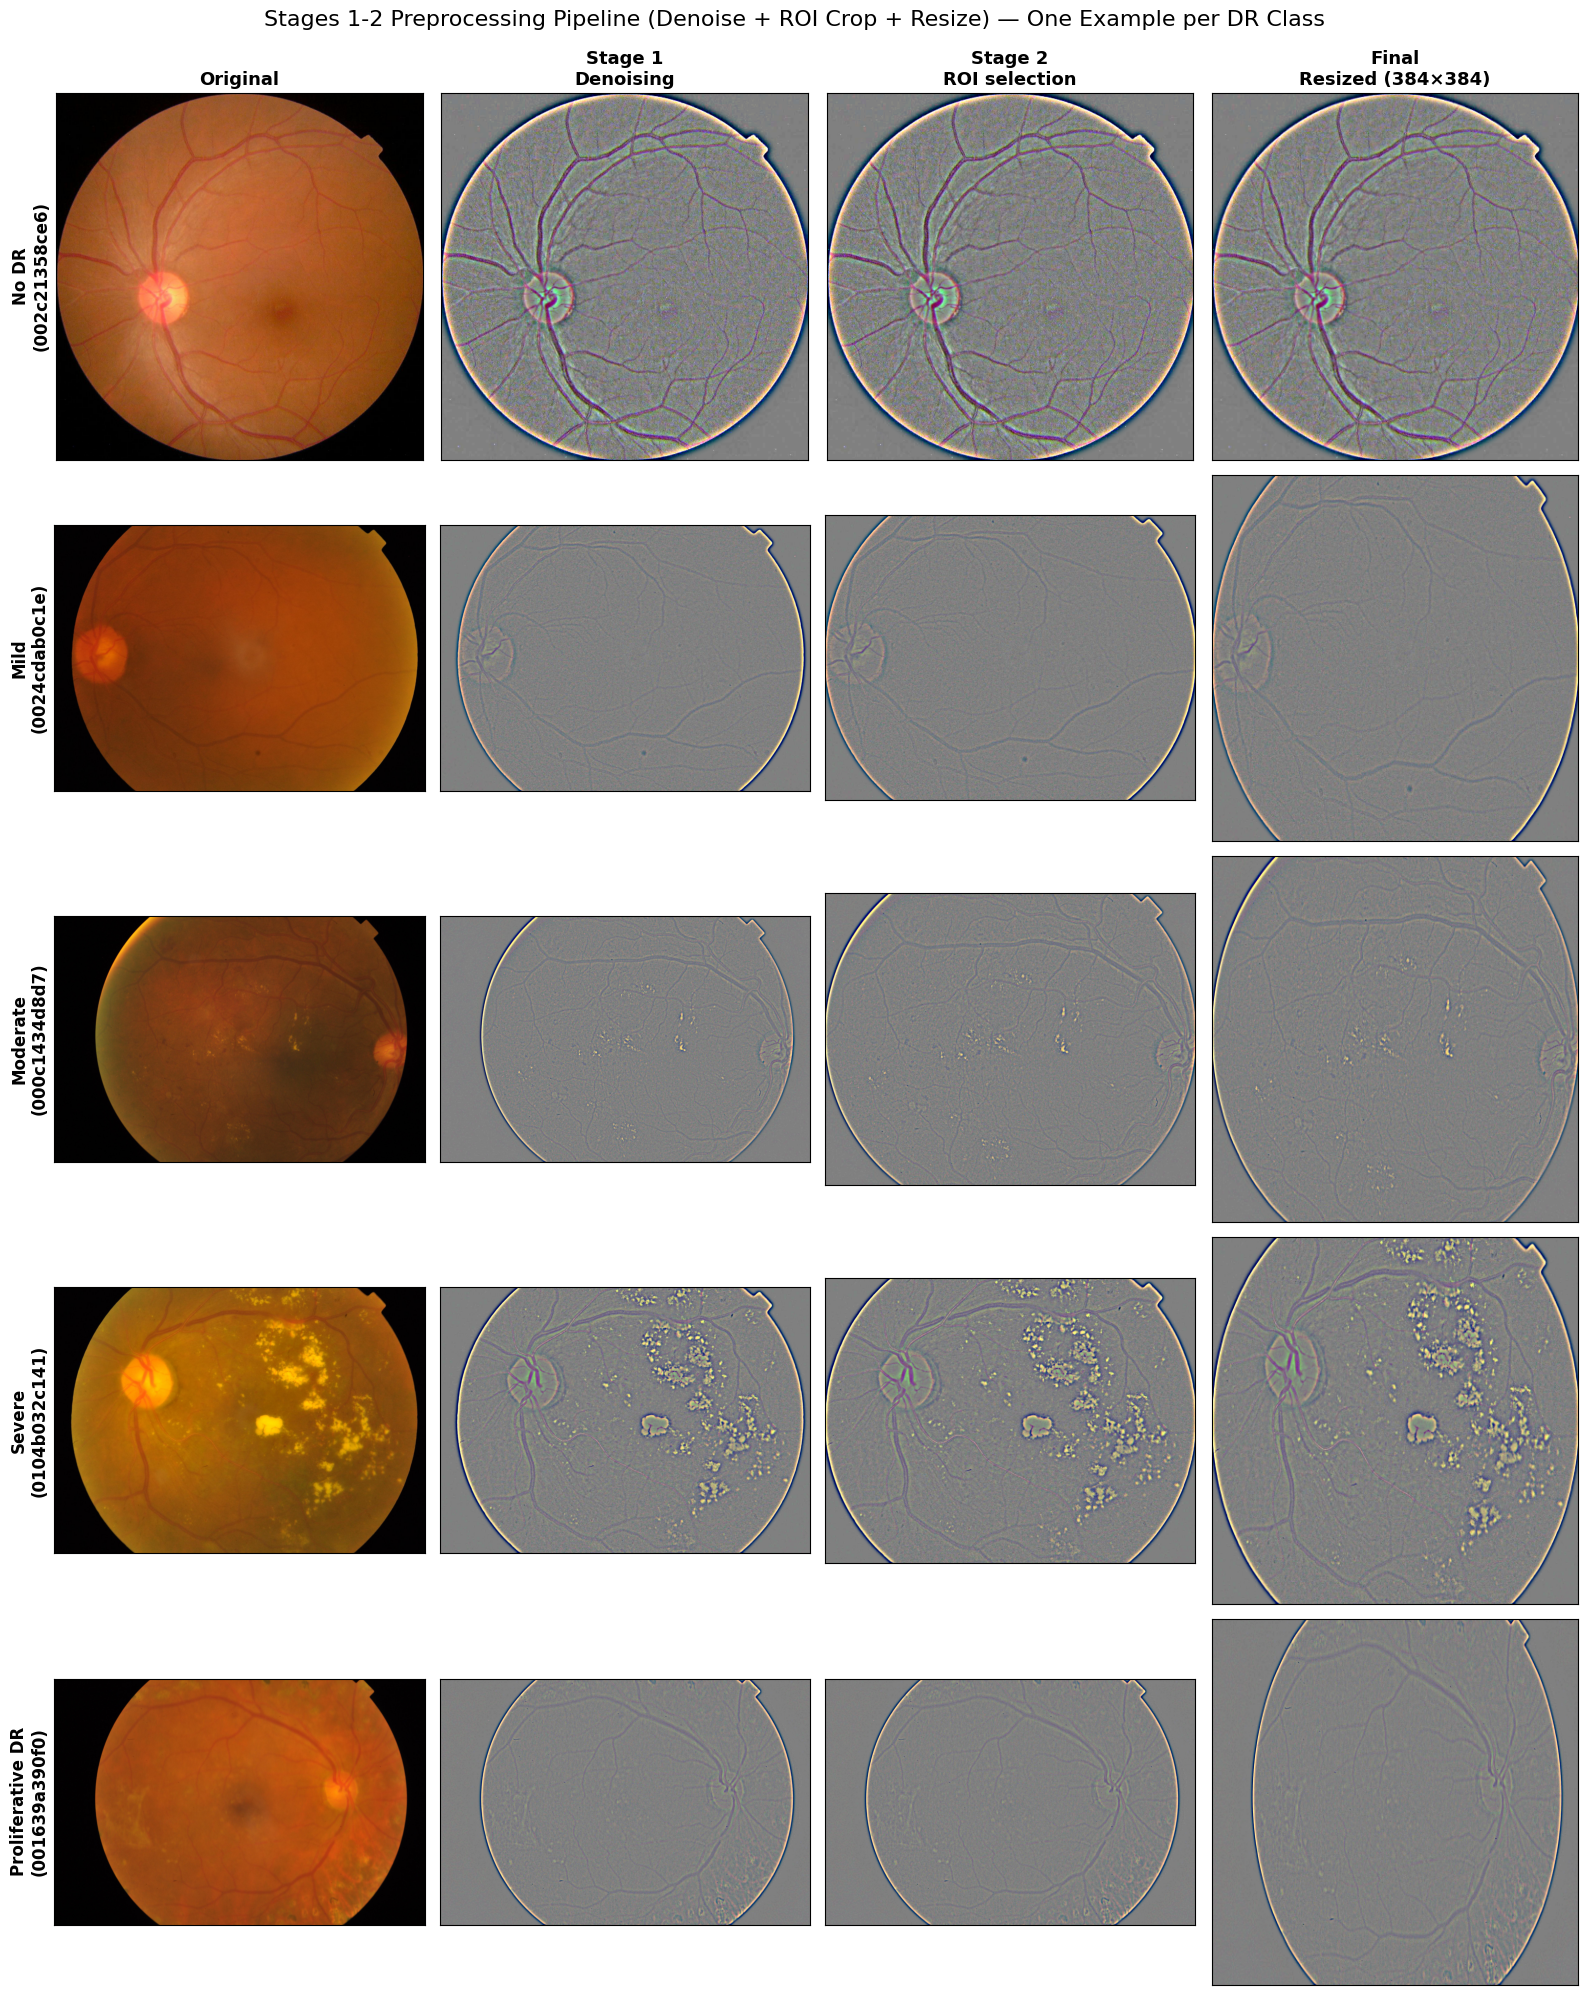

In [8]:
# ---------------------------
# 2.5 Visualize Preprocessing Stages (per class)
# ---------------------------
import os, cv2, numpy as np, pandas as pd
import matplotlib.pyplot as plt

CLASS_NAMES = {
    0: "No DR",
    1: "Mild",
    2: "Moderate",
    3: "Severe",
    4: "Proliferative DR",
}
STAGE_TITLES = [
    "Original",
    "Stage 1\nDenoising",
    "Stage 2\nROI selection",
    "Final\nResized (384×384)",
]

# Ensure we have a valid folder to read from
search_dirs = [
    TRAIN_IMAGES_DIR,
    f"{RAW_DIR}/train_images",
    "/content/drive/MyDrive/DR_Project/APTOS/train_images",
]
valid_raw_dir = next(
    (d for d in search_dirs if os.path.exists(d) and len(os.listdir(d)) > 0), None
)

if valid_raw_dir is None:
    raise FileNotFoundError(f"Could not find raw images in any of: {search_dirs}")

print(f"Using raw images from: {valid_raw_dir}")
print(f"{'Class':<18s} {'id_code used':<15s}")
print("-" * 34)

fig, axes = plt.subplots(5, 4, figsize=(16, 20))

for row, class_id in enumerate(range(5)):
    class_df = df[df["diagnosis"] == class_id]
    if len(class_df) == 0:
        print(f"{CLASS_NAMES[class_id]:<18s} (no samples in train_df)")
        for col in range(4):
            axes[row, col].axis("off")
        continue

    image_id = class_df.iloc[0]["id_code"]
    print(f"{CLASS_NAMES[class_id]:<18s} {image_id:<15s}")

    # Check for .png, .jpg, or .jpeg
    raw = None
    for ext in [".png", ".jpg", ".jpeg"]:
        candidate = os.path.join(valid_raw_dir, f"{image_id}{ext}")
        if os.path.exists(candidate):
            raw = cv2.imread(candidate)
            break

    if raw is None:
        print(f"Warning: Could not read image for {image_id}")
        for col in range(4):
            axes[row, col].axis("off")
        continue

    raw = cv2.cvtColor(raw, cv2.COLOR_BGR2RGB)

    # Stages 1 & 2 only:
    s1 = stage1_denoise(raw)
    s2 = stage2_roi_selection(s1)
    s_final = cv2.resize(s2, (384, 384), interpolation=cv2.INTER_AREA)

    for col, img in enumerate([raw, s1, s2, s_final]):
        ax = axes[row, col]
        ax.imshow(img)
        ax.set_xticks([])
        ax.set_yticks([])
        if row == 0:
            ax.set_title(STAGE_TITLES[col], fontsize=13, fontweight="bold")
        if col == 0:
            ax.set_ylabel(
                f"{CLASS_NAMES[class_id]}\n({image_id})", fontsize=12, fontweight="bold"
            )

plt.suptitle(
    "Stages 1-2 Preprocessing Pipeline (Denoise + ROI Crop + Resize) — One Example per DR Class",
    fontsize=16,
    y=0.995,
)
plt.tight_layout()

viz_path = f"{DATA_DIR}/preprocessing_stages_per_class.png"
plt.savefig(viz_path, dpi=150, bbox_inches="tight")
print(f"\nSaved per-class stage grid to: {viz_path}")
plt.show()


In [9]:
# ============================================================================
# 3. TRAIN / VALIDATION SPLIT
# ============================================================================
# Creates an 80/20 stratified split of the APTOS training data.
# 'Stratified' means each split preserves the original class distribution,
# which is critical because APTOS is heavily imbalanced:
#   Class 0 (No DR):          ~49% of images
#   Class 1 (Mild):           ~9%
#   Class 2 (Moderate):       ~27%
#   Class 3 (Severe):         ~5%
#   Class 4 (Proliferative):  ~10%
#
# The split CSVs are persisted to Google Drive so re-runs use the same split
# (essential for fair comparison across experiments).
# ============================================================================
if os.path.exists(TRAIN_SPLIT_CSV) and os.path.exists(VAL_SPLIT_CSV):
    # Load previously saved splits (ensures consistency across sessions)
    train_df = pd.read_csv(TRAIN_SPLIT_CSV)
    val_df = pd.read_csv(VAL_SPLIT_CSV)
else:
    # Create new stratified split: 80% train, 20% validation
    train_df, val_df = train_test_split(
        df, test_size=0.2, stratify=df["diagnosis"], random_state=42
    )
    # Save splits to Drive for reproducibility
    train_df.to_csv(TRAIN_SPLIT_CSV, index=False)
    val_df.to_csv(VAL_SPLIT_CSV, index=False)

# Print class distributions to verify stratification worked correctly
print("Train distribution:\n", train_df["diagnosis"].value_counts().sort_index())
print("Val distribution:\n", val_df["diagnosis"].value_counts().sort_index())


Train distribution:
 diagnosis
0    1444
1     296
2     799
3     154
4     236
Name: count, dtype: int64
Val distribution:
 diagnosis
0    361
1     74
2    200
3     39
4     59
Name: count, dtype: int64


In [10]:
# ============================================================================
# 4. DATASET CLASS & AUGMENTATION PIPELINE
# ============================================================================


class APTOSDataset(Dataset):
    """Custom PyTorch Dataset for the APTOS 2019 Diabetic Retinopathy dataset.

    Each sample returns:
        image:  A torch.Tensor of shape (3, 384, 384), normalized to ImageNet stats
        label:  An integer label 0-4 representing DR severity grade

    The 'transform' parameter should be an Albumentations Compose pipeline.
    Images are loaded from pre-processed PNGs (already denoised, cropped, sharpened).
    """

    def __init__(self, dataframe, image_dir, transform=None):
        self.df = dataframe.reset_index(drop=True)  # Reset index for clean iloc access
        self.image_dir = image_dir  # Directory containing preprocessed images
        self.transform = transform  # Albumentations augmentation pipeline

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        image_id = self.df.loc[idx, "id_code"]
        label = int(
            self.df.loc[idx, "diagnosis"]
        )  # DR grade: 0=No DR, 1=Mild, ..., 4=Proliferative
        path = os.path.join(self.image_dir, image_id + ".png")

        # Load pre-processed image as RGB numpy array
        image = np.array(Image.open(path).convert("RGB"))
        if self.transform:
            image = self.transform(image=image)[
                "image"
            ]  # Albumentations returns a dict
        return image, torch.tensor(label, dtype=torch.long)


# ============================================================================
# AUGMENTATION PIPELINES
# ============================================================================
# Training augmentations are aggressive but carefully chosen for DR grading:
# - Spatial transforms (crop, flip, rotate) increase viewpoint diversity
# - Color transforms (CLAHE, brightness, hue) simulate different cameras
# - Noise/blur simulate image quality variations
# - CoarseDropout acts as regularization (similar to Cutout/Random Erasing)
#
# IMPORTANT: Geometric distortions (ElasticTransform, GridDistortion) are
# intentionally EXCLUDED because they distort microaneurysm shapes, which
# are critical for distinguishing DR severity grades.
# ============================================================================

train_tfms = A.Compose(
    [
        # --- Spatial transforms ---
        A.RandomResizedCrop(
            size=(384, 384),  # Must match Swin Transformer input size
            scale=(0.75, 1.0),  # Crop 75-100% of the image area
            ratio=(
                0.90,
                1.10,
            ),  # Near-square aspect ratios (retinal images are ~square)
            p=1.0,  # Always apply (needed for consistent 384×384 output)
        ),
        A.HorizontalFlip(p=0.5),  # 50% chance of horizontal flip
        A.VerticalFlip(p=0.5),  # 50% chance of vertical flip
        A.ShiftScaleRotate(
            shift_limit=0.05,  # Translate up to 5% of image size
            scale_limit=0.10,  # Scale ±10%
            rotate_limit=20,  # Rotate ±20 degrees
            border_mode=0,  # Fill borders with black (cv2.BORDER_CONSTANT)
            p=0.75,  # Apply 75% of the time
        ),
        # --- Color & contrast transforms ---
        # Geometric distortions REMOVED (would destroy microaneurysm features)
        A.CLAHE(
            clip_limit=4.0, tile_grid_size=(8, 8), p=0.55
        ),  # Contrast-Limited Adaptive Histogram
        # Equalization: enhances local contrast
        A.RandomBrightnessContrast(
            brightness_limit=0.20,  # ±20% brightness shift
            contrast_limit=0.20,  # ±20% contrast shift
            p=0.65,  # Apply 65% of the time
        ),
        A.HueSaturationValue(
            hue_shift_limit=10,  # Small hue shifts (large shifts would be unrealistic)
            sat_shift_limit=25,  # Moderate saturation variation
            val_shift_limit=20,  # Moderate value/brightness variation
            p=0.50,
        ),
        # --- Noise & blur (simulate camera quality variations) ---
        A.GaussNoise(var_limit=(5.0, 30.0), p=0.20),  # Gaussian noise, 20% chance
        A.GaussianBlur(blur_limit=(3, 5), p=0.25),  # Slight blur, 25% chance
        # --- Regularization dropout (similar to Cutout) ---
        A.CoarseDropout(
            max_holes=8,  # Up to 8 rectangular patches dropped
            max_height=48,  # Each patch up to 48×48 pixels
            max_width=48,
            min_holes=1,  # At least 1 patch
            min_height=12,
            min_width=12,
            fill_value=0,  # Fill dropped regions with black
            p=0.35,  # Apply 35% of the time
        ),
        # --- Final normalization to ImageNet statistics ---
        # These mean/std values are the standard ImageNet normalization
        # required by all timm pretrained models
        A.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ToTensorV2(),  # Convert numpy HWC → PyTorch CHW tensor
    ]
)

# Validation: NO augmentation, only normalize and convert to tensor
val_tfms = A.Compose(
    [
        A.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ToTensorV2(),
    ]
)


/usr/local/lib/python3.13/dist-packages/albumentations/core/validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)
/tmp/ipykernel_74078/3137770092.py:94: UserWarning: Argument(s) 'var_limit' are not valid for transform GaussNoise
  A.GaussNoise(var_limit=(5.0, 30.0), p=0.20),  # Gaussian noise, 20% chance
/tmp/ipykernel_74078/3137770092.py:97: UserWarning: Argument(s) 'max_holes, max_height, max_width, min_holes, min_height, min_width, fill_value' are not valid for transform CoarseDropout
  A.CoarseDropout(


In [ ]:
# Check available CPU cores — useful for setting num_workers in DataLoader.
# On Colab, this typically returns 2 (but we use num_workers=0 to avoid
# multiprocessing issues with Google Drive file I/O).
os.cpu_count()


2

In [12]:
# ============================================================================
# 5. CLASS BALANCING — WeightedRandomSampler for imbalanced APTOS dataset
# ============================================================================
# APTOS has severe class imbalance (Class 0 has ~10× more samples than Class 3).
# Without balancing, the model would learn to predict "No DR" for everything
# and still achieve ~49% accuracy.
#
# Strategy: WeightedRandomSampler assigns higher sampling probability to
# minority classes, so each epoch sees roughly equal numbers of each class.
# This is preferred over loss-function weighting (which we tried and found
# to over-penalize majority classes when combined with the sampler).
# ============================================================================

labels_np = train_df["diagnosis"].values  # Array of all training labels
class_counts = np.bincount(labels_np)  # Count images per class: [N0, N1, N2, N3, N4]
max_class_count = int(class_counts.max())  # Size of the largest class (Class 0)

# compute_class_weight("balanced"): returns weight = N_total / (N_classes * N_class)
# i.e., rare classes get high weights, common classes get low weights
class_weights_np = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(labels_np),
    y=labels_np,
)
class_weights = torch.tensor(class_weights_np, dtype=torch.float32)

# Per-sample weights: each sample gets the weight of its class
sample_weights_np = class_weights_np[labels_np]

# Total samples drawn per epoch = 5 × max_class_count
# This ensures we see enough of each class (with replacement/oversampling)
num_sampler_samples = 5 * max_class_count

# WeightedRandomSampler: samples with replacement, probability proportional to weight
# Minority classes (Severe, Mild) get sampled much more often than their actual count
sampler = WeightedRandomSampler(
    weights=torch.DoubleTensor(sample_weights_np),
    num_samples=num_sampler_samples,
    replacement=True,  # Required: we need to oversample rare classes
)

# --- Create Dataset and DataLoader ---
train_dataset = APTOSDataset(train_df, IMAGE_DIR, train_tfms)
val_dataset = APTOSDataset(val_df, IMAGE_DIR, val_tfms)

train_loader = DataLoader(
    train_dataset,
    batch_size=8,
    sampler=sampler,  # batch_size=8: safe for T4 GPU (15GB)
    num_workers=0,
    pin_memory=True,  # num_workers=0: avoids Drive I/O issues
)
val_loader = DataLoader(
    val_dataset,
    batch_size=4,
    shuffle=False,  # Smaller batch for validation (saves memory)
    num_workers=0,
    pin_memory=True,
)

# --- Print expected sampling statistics per class ---
# This verifies the sampler is working: each class should have roughly
# equal expected draws despite the imbalanced original distribution
total_w = sample_weights_np.sum()
print("Effective draws/epoch after WeightedRandomSampler:")
for c in range(5):
    mask = labels_np == c
    class_w_sum = sample_weights_np[mask].sum()  # Total weight for this class
    expected = (class_w_sum / total_w) * num_sampler_samples  # Expected draws
    unique_imgs = mask.sum()  # Actual unique images
    rep = expected / unique_imgs  # Repetition factor
    print(
        f"  Class {c}: {unique_imgs:4d} unique imgs → ~{expected:.0f} draws  ({rep:.2f}× repetition)"
    )
print(f"  Total draws / epoch: {num_sampler_samples}")


Effective draws/epoch after WeightedRandomSampler:
  Class 0: 1444 unique imgs → ~1444 draws  (1.00× repetition)
  Class 1:  296 unique imgs → ~1444 draws  (4.88× repetition)
  Class 2:  799 unique imgs → ~1444 draws  (1.81× repetition)
  Class 3:  154 unique imgs → ~1444 draws  (9.38× repetition)
  Class 4:  236 unique imgs → ~1444 draws  (6.12× repetition)
  Total draws / epoch: 7220


In [13]:
# ============================================================================
# 6. MODEL ARCHITECTURE — Swin Transformer Base + CBAM Attention
# ============================================================================
# Architecture overview:
#   Input (3×384×384) → Swin Transformer Base (backbone) → (B, H, W, 1024)
#   → CBAM attention → AdaptiveAvgPool → LayerNorm → Dropout → FC(512) → GELU
#   → Dropout → FC(5) → logits
#
# The Swin Transformer uses shifted windows for self-attention, making it
# efficient for high-resolution images (384×384). CBAM adds channel and
# spatial attention to help the model focus on disease-relevant features.
# ============================================================================


class CBAM(nn.Module):
    """Convolutional Block Attention Module (CBAM).

    Applies two sequential attention mechanisms:
      1. Channel Attention: "what" features to focus on
         - Global avg pool + Global max pool → shared MLP → sigmoid → scale channels
      2. Spatial Attention: "where" to focus in the image
         - Mean + Max across channels → 7×7 conv → sigmoid → scale spatial locations

    This helps the model attend to disease-relevant regions (e.g., hemorrhages,
    exudates) and ignore irrelevant background regions.

    Args:
        channels:       Number of input feature channels (1024 for Swin Base)
        reduction:      Channel reduction ratio for the MLP bottleneck (16 → 1024/16=64)
        spatial_kernel: Kernel size for spatial attention conv (7×7 captures local context)
    """

    def __init__(self, channels, reduction=16, spatial_kernel=7):
        super().__init__()
        hidden = max(
            channels // reduction, 1
        )  # Bottleneck dimension (64 for channels=1024)

        # Shared MLP for channel attention (applied to both avg-pool and max-pool)
        self.mlp = nn.Sequential(
            nn.Linear(channels, hidden, bias=False),  # 1024 → 64 (bottleneck)
            nn.ReLU(inplace=True),
            nn.Linear(hidden, channels, bias=False),  # 64 → 1024 (restore)
        )

        # Spatial attention: 7×7 conv over 2-channel input (avg + max across channels)
        self.spatial = nn.Conv2d(
            2, 1, kernel_size=spatial_kernel, padding=spatial_kernel // 2, bias=False
        )

    def forward(self, x):
        b, c, h, w = x.shape

        # --- Channel Attention ---
        # Pool spatial dimensions to get per-channel descriptors
        avg_pool = F.adaptive_avg_pool2d(x, 1).view(
            b, c
        )  # (B, C): average response per channel
        max_pool = F.adaptive_max_pool2d(x, 1).view(
            b, c
        )  # (B, C): max response per channel
        # Pass both through the SAME MLP, add results, sigmoid → channel weights
        channel_att = torch.sigmoid(self.mlp(avg_pool) + self.mlp(max_pool)).view(
            b, c, 1, 1
        )
        x = x * channel_att  # Element-wise scaling of each channel

        # --- Spatial Attention ---
        # Compute per-pixel descriptors by pooling across channels
        avg_out = torch.mean(
            x, dim=1, keepdim=True
        )  # (B, 1, H, W): mean across channels
        max_out, _ = torch.max(
            x, dim=1, keepdim=True
        )  # (B, 1, H, W): max across channels
        # Concatenate, apply 7×7 conv, sigmoid → spatial attention map
        spatial_att = torch.sigmoid(self.spatial(torch.cat([avg_out, max_out], dim=1)))
        x = x * spatial_att  # Element-wise scaling of each spatial position

        return x


class SwinTeacher(nn.Module):
    """Swin Transformer Base (384×384) + CBAM + classification head.

    This is the "teacher" model — a large, accurate model that will later
    be used for knowledge distillation to train a smaller student model.

    Architecture:
        - Backbone: swin_base_patch4_window12_384 pretrained on ImageNet-22K
          (88M params, 12×12 window attention, 4×4 patch embedding)
        - CBAM: channel + spatial attention on backbone features (1024-d)
        - Head: AdaptiveAvgPool → LayerNorm → Dropout → FC(512) → GELU → FC(5)

    Args:
        num_classes:    Number of DR grades (5: No DR, Mild, Moderate, Severe, Proliferative)
        dropout:        Dropout rate in the classification head (0.35)
        drop_path_rate: Stochastic depth rate in the Swin backbone (0.15)
    """

    def __init__(self, num_classes=5, dropout=0.35, drop_path_rate=0.15):
        super().__init__()
        # Load pretrained Swin Transformer Base from timm
        # - num_classes=0:  removes the original classification head
        # - global_pool="": disables global pooling (we do it ourselves after CBAM)
        # - drop_path_rate: stochastic depth for regularization during fine-tuning
        self.backbone = timm.create_model(
            "swin_base_patch4_window12_384.ms_in22k",  # Pretrained on ImageNet-22K (14M images)
            pretrained=True,
            num_classes=0,  # Remove default head
            global_pool="",  # Keep spatial dimensions (don't pool yet)
            drop_rate=0.0,  # No standard dropout in backbone (we add it in head)
            drop_path_rate=drop_path_rate,  # Stochastic depth: randomly drops entire layers
        )

        # CBAM attention on the 1024-d backbone features
        self.cbam = CBAM(channels=1024)

        # Classification head: pool → normalize → dropout → FC → GELU → dropout → FC
        self.head = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),  # (B, 1024, H, W) → (B, 1024, 1, 1)
            nn.Flatten(),  # (B, 1024, 1, 1) → (B, 1024)
            nn.LayerNorm(1024),  # Normalize features (stabilizes training)
            nn.Dropout(dropout),  # 35% dropout for regularization
            nn.Linear(1024, 512),  # 1024 → 512 intermediate features
            nn.GELU(),  # Gaussian Error Linear Unit (smoother than ReLU)
            nn.Dropout(dropout),  # Another 35% dropout
            nn.Linear(512, num_classes),  # 512 → 5 class logits
        )

    def forward(self, x):
        # Extract features using the Swin backbone
        feat = self.backbone.forward_features(x)  # Output shape varies by timm version
        # Swin's output may be (B, H, W, C) — we need (B, C, H, W) for CBAM convolutions
        if feat.dim() == 4 and feat.shape[-1] == 1024:
            feat = feat.permute(
                0, 3, 1, 2
            ).contiguous()  # (B, H, W, 1024) → (B, 1024, H, W)
        feat = self.cbam(feat)  # Apply channel + spatial attention
        return self.head(feat)  # Pool, normalize, classify


# --- Initialize model and move to GPU ---
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = SwinTeacher(num_classes=5, dropout=0.35, drop_path_rate=0.15).to(device)

# --- Freeze backbone for initial warmup phase ---
# During the first few epochs, only the CBAM and classification head are trained.
# This prevents the pretrained backbone from being corrupted by large random gradients
# from the randomly-initialized head. After warmup, the backbone is unfrozen.
for p in model.backbone.parameters():
    p.requires_grad = False


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


In [ ]:
# ============================================================================
# 7. LOSS FUNCTION / OPTIMIZER / LEARNING RATE SCHEDULER
# ============================================================================


class FocalLoss(nn.Module):
    """Focal Loss — down-weights easy examples, focuses training on hard ones.

    Standard Cross-Entropy treats all misclassifications equally. Focal Loss
    adds a modulating factor (1 - pt)^gamma that:
      - Reduces loss contribution from well-classified examples (high pt)
      - Keeps full loss for hard/misclassified examples (low pt)

    This is especially useful for DR grading where some severity boundaries
    are subtle (e.g., Moderate vs. Severe) and produce many "hard" examples.

    Formula: FL(pt) = -alpha_t * (1 - pt)^gamma * log(pt)

    Args:
        alpha:  Per-class weights tensor (None = unweighted, since we use sampler instead)
        gamma:  Focusing parameter (2.0 = standard, higher = more focus on hard examples)
    """

    def __init__(self, alpha=None, gamma=2.0):
        super().__init__()
        self.alpha = alpha
        self.gamma = gamma

    def forward(self, inputs, targets):
        if self.alpha is not None:
            ce = F.cross_entropy(inputs, targets, weight=self.alpha, reduction="none")
        else:
            ce = F.cross_entropy(inputs, targets, reduction="none")
        pt = torch.exp(-ce)  # pt = probability of correct class
        return (((1 - pt) ** self.gamma) * ce).mean()  # Focal modulation


# NOTE: We do NOT pass class weights to FocalLoss (alpha=None) because we
# are ALREADY using WeightedRandomSampler for class balancing. Using both
# would double-penalize and actually hurt minority class convergence.
criterion = FocalLoss(alpha=None, gamma=2.0)

# --- Optimizer: AdamW with differential learning rates ---
# The backbone uses a much lower LR (1e-5) than the new CBAM+head (1e-4)
# because the backbone is already pretrained — we want to fine-tune gently,
# not destroy the learned features.
optimizer = torch.optim.AdamW(
    [
        {
            "params": model.backbone.parameters(),
            "lr": 1e-5,
        },  # Backbone: gentle fine-tuning
        {
            "params": list(model.cbam.parameters()) + list(model.head.parameters()),
            "lr": 1e-4,
        },  # Head: faster learning
    ],
    weight_decay=1e-4,  # L2 regularization to prevent overfitting
)

# --- Learning Rate Scheduler: Cosine Annealing ---
# Smoothly decays the learning rate from initial value to near-zero over
# T_max=100 epochs, following a cosine curve. This avoids the need for
# manual LR step schedules and generally trains smoother.
from torch.optim.lr_scheduler import CosineAnnealingLR

scheduler = CosineAnnealingLR(optimizer, T_max=100)

# --- Mixed Precision Training ---
# GradScaler handles automatic loss scaling for float16 training.
# This roughly doubles training speed and halves memory usage on
# GPUs with Tensor Cores (T4, V100, A100).
scaler = torch.amp.GradScaler("cuda")


In [ ]:
# ============================================================================
# 8. VALIDATION FUNCTION & MIXUP UTILITIES
# ============================================================================


def evaluate(model, loader, criterion, device):
    """Run the model on a DataLoader and compute all evaluation metrics.

    Runs in eval mode (no dropout, no batch norm updates) with gradients
    disabled for speed.

    Returns:
        avg_loss:  Mean loss over all batches
        acc:       Overall accuracy (fraction correct)
        qwk:       Quadratic Weighted Kappa — PRIMARY metric for ordinal classification.
                   Penalizes predictions proportional to the SQUARE of their distance
                   from the true grade (e.g., predicting 0 for a grade-4 is penalized
                   16× more than predicting 3 for a grade-4).
        precision: Macro-averaged precision across all classes
        recall:    Macro-averaged recall across all classes
        f1:        Macro-averaged F1 score
        targets:   List of true labels (for classification_report)
        preds:     List of predicted labels
    """
    model.eval()  # Switch to evaluation mode (disables dropout & batchnorm updates)
    running_loss = 0.0
    preds, targets = [], []

    with torch.no_grad():  # Disable gradient computation for speed
        for images, labels in loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)
            outputs = model(images)  # Forward pass
            loss = criterion(outputs, labels)  # Compute loss
            running_loss += loss.item()
            preds.extend(
                outputs.argmax(dim=1).detach().cpu().numpy().tolist()
            )  # Predicted class
            targets.extend(labels.detach().cpu().numpy().tolist())  # True class

    avg_loss = running_loss / max(len(loader), 1)
    acc = accuracy_score(targets, preds)
    qwk = cohen_kappa_score(targets, preds, weights="quadratic")  # PRIMARY metric

    # Macro-averaged: treats all classes equally (important for imbalanced data)
    precision, recall, f1, _ = precision_recall_fscore_support(
        targets, preds, average="macro", zero_division=0
    )

    return avg_loss, acc, qwk, precision, recall, f1, targets, preds


# ============================================================================
# MIXUP DATA AUGMENTATION — Currently DISABLED
# ============================================================================
# MixUp creates virtual training examples by linearly interpolating between
# pairs of images and their labels. It works well for natural image classification
# but HURTS ordinal DR grading because interpolating between grade-0 and grade-4
# images creates nonsensical "grade-2" targets that confuse the model.
# ============================================================================
MIXUP_ALPHA = 0.0  # Set to 0 to disable (no Beta distribution sampling)
MIXUP_PROB = 0.0  # Set to 0 to disable (never apply MixUp)


def mixup_data(x, y, alpha, device):
    """Create MixUp-augmented batch by interpolating random pairs."""
    lam = np.random.beta(alpha, alpha) if alpha > 0 else 1.0  # Interpolation weight
    index = torch.randperm(x.size(0)).to(device)  # Random pairing
    mixed_x = lam * x + (1.0 - lam) * x[index]  # Interpolated images
    return mixed_x, y, y[index], lam


def mixup_criterion(criterion, pred, y_a, y_b, lam):
    """Compute MixUp loss: weighted average of losses for both label sets."""
    return lam * criterion(pred, y_a) + (1.0 - lam) * criterion(pred, y_b)


In [16]:
# ============================================================================
# 9. TRAINING LOOP — with automatic checkpoint resume, AMP, early stopping
# ============================================================================

checkpoint_path = os.path.join(
    CHECKPOINT_DIR, "latest_checkpoint.pth"
)  # Full state resume point
best_model_path = os.path.join(CHECKPOINT_DIR, "best_model.pth")  # Best QWK weights

# --- Hyperparameters ---
NUM_EPOCHS = 100  # Maximum epochs
PATIENCE = 10  # Early stopping patience on QWK
MIN_DELTA = 0.005  # Minimum QWK improvement
freeze_epochs = 5  # Warmup epochs with frozen backbone

# --- Automatic Resume Checkpoint Logic ---
RESUME = True  # Set to False if you ever want to force a completely fresh start

if RESUME and os.path.exists(checkpoint_path):
    print(f"Found existing checkpoint at: {checkpoint_path}")
    checkpoint = torch.load(checkpoint_path, map_location=device, weights_only=False)
    model.load_state_dict(checkpoint["model"])
    optimizer.load_state_dict(checkpoint["optimizer"])
    scaler.load_state_dict(checkpoint["scaler"])
    START_EPOCH = checkpoint["epoch"] + 1
    best_qwk = checkpoint["best_qwk"]
    patience_counter = checkpoint["patience_counter"]
    backbone_unfrozen = checkpoint.get("backbone_unfrozen", False)
    history = checkpoint.get("history", [])

    print(f"Resuming training from epoch {START_EPOCH + 1}/{NUM_EPOCHS}...")
    print(
        f"Best QWK recorded so far: {best_qwk:.4f} | Patience counter: {patience_counter}/{PATIENCE}"
    )

    if backbone_unfrozen:
        for p in model.backbone.parameters():
            p.requires_grad = True
        print("Backbone was already unfrozen in checkpoint.")
else:
    START_EPOCH = 0
    best_qwk = 0.0
    patience_counter = 0
    backbone_unfrozen = False
    history = []
    print("No checkpoint found (or RESUME=False). Starting fresh from epoch 1.")

# --- Training Loop ---
for epoch in range(START_EPOCH, NUM_EPOCHS):
    # Phase transition: unfreeze backbone after warmup
    if (not backbone_unfrozen) and epoch >= freeze_epochs:
        for p in model.backbone.parameters():
            p.requires_grad = True
        backbone_unfrozen = True
        print(f"Epoch {epoch + 1}: backbone unfrozen")

    model.train()
    running_loss = 0.0

    pbar = tqdm(train_loader, desc=f"Epoch {epoch + 1}/{NUM_EPOCHS}", leave=False)
    for images, labels in pbar:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        # 1. Reset gradients at start of batch
        optimizer.zero_grad(set_to_none=True)

        # 2. Forward pass with AMP
        if hasattr(torch, "amp") and hasattr(torch.amp, "autocast"):
            with torch.amp.autocast("cuda"):
                outputs = model(images)
                loss = criterion(outputs, labels)
        else:
            with torch.cuda.amp.autocast():
                outputs = model(images)
                loss = criterion(outputs, labels)

        # 3. Backward pass & optimizer step
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        scaler.step(optimizer)
        scaler.update()

        # 4. Explicitly reset gradients after batch (prevents accumulation)
        optimizer.zero_grad(set_to_none=True)

        running_loss += loss.item()
        pbar.set_postfix(train_loss=loss.item())

    scheduler.step()

    # --- Evaluate on validation set ---
    train_loss = running_loss / max(len(train_loader), 1)
    val_loss, val_acc, val_qwk, val_prec, val_rec, val_f1, y_true, y_pred = evaluate(
        model, val_loader, criterion, device
    )

    print(
        f"Epoch {epoch + 1:03d} | train_loss={train_loss:.4f} | val_loss={val_loss:.4f} | "
        f"val_acc={val_acc:.4f} | val_qwk={val_qwk:.4f} | "
        f"prec={val_prec:.4f} | rec={val_rec:.4f} | f1={val_f1:.4f}"
    )

    history.append(
        {
            "epoch": epoch + 1,
            "train_loss": train_loss,
            "val_loss": val_loss,
            "val_acc": val_acc,
            "val_qwk": val_qwk,
            "val_prec": val_prec,
            "val_rec": val_rec,
            "val_f1": val_f1,
        }
    )

    # Save best model weights
    if val_qwk > best_qwk + MIN_DELTA:
        best_qwk = val_qwk
        patience_counter = 0
        torch.save(model.state_dict(), best_model_path)
        print(f"Best model saved | best_qwk={best_qwk:.4f}  acc={val_acc:.4f}")
    else:
        patience_counter += 1
        print(f"No improvement. Patience: {patience_counter}/{PATIENCE}")

    # Save full state checkpoint for resume
    torch.save(
        {
            "epoch": epoch,
            "model": model.state_dict(),
            "optimizer": optimizer.state_dict(),
            "scaler": scaler.state_dict(),
            "best_qwk": best_qwk,
            "patience_counter": patience_counter,
            "backbone_unfrozen": backbone_unfrozen,
            "history": history,
        },
        checkpoint_path,
    )

    if patience_counter >= PATIENCE:
        print("Early stopping triggered.")
        break


Found existing checkpoint at: /content/drive/MyDrive/DR_Project/checkpoints/latest_checkpoint.pth
Resuming training from epoch 23/100...
Best QWK recorded so far: 0.9043 | Patience counter: 13/10
Backbone was already unfrozen in checkpoint.


Epoch 23/100:   0%|          | 0/903 [00:00<?, ?it/s]

Epoch 023 | train_loss=0.0632 | val_loss=0.7517 | val_acc=0.8281 | val_qwk=0.8930 | prec=0.7026 | rec=0.6640 | f1=0.6746
No improvement. Patience: 14/10
Early stopping triggered.


Best model loaded.
Final Val Loss: 0.3077
Final Val Acc : 0.8213
Final Val QWK : 0.9043
Final Val Prec: 0.6871
Final Val Rec : 0.6841
Final Val F1  : 0.6820

Classification report:
               precision    recall  f1-score   support

        No DR     0.9855    0.9446    0.9646       361
         Mild     0.5833    0.6622    0.6203        74
     Moderate     0.7642    0.8100    0.7864       200
       Severe     0.3913    0.4615    0.4235        39
Proliferative     0.7111    0.5424    0.6154        59

     accuracy                         0.8213       733
    macro avg     0.6871    0.6841    0.6820       733
 weighted avg     0.8308    0.8213    0.8243       733

Saved history to: /content/drive/MyDrive/DR_Project/checkpoints/training_history.csv


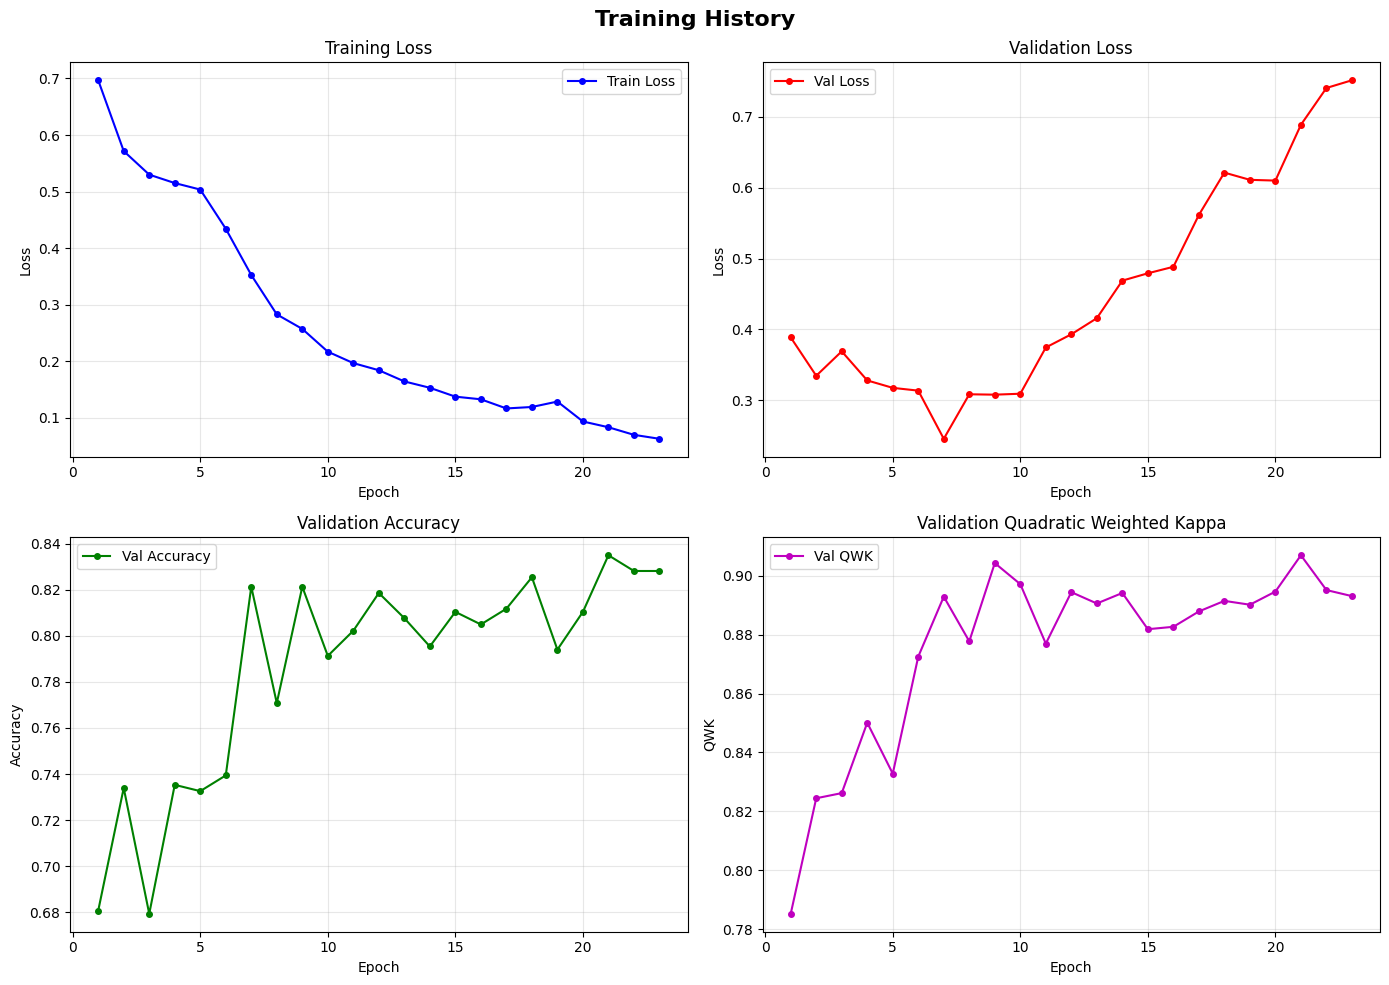

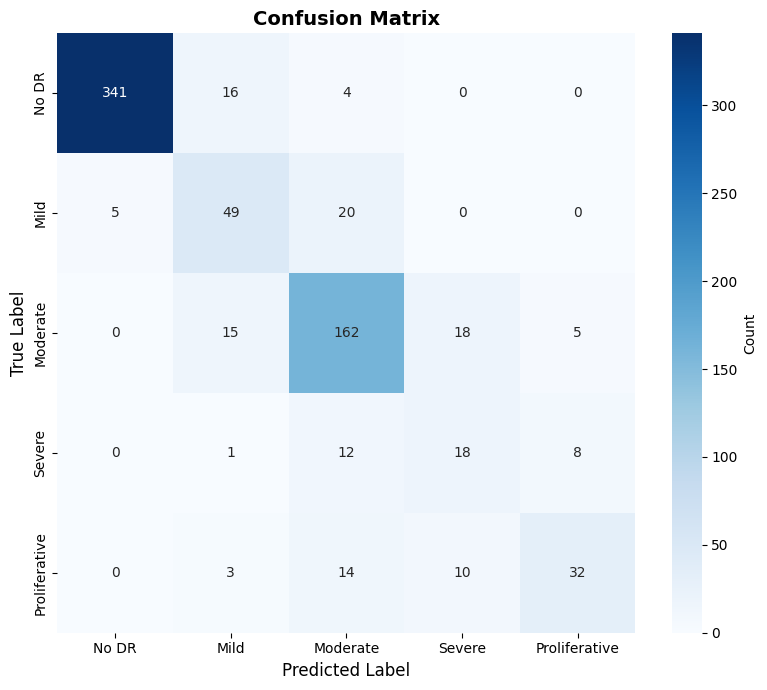

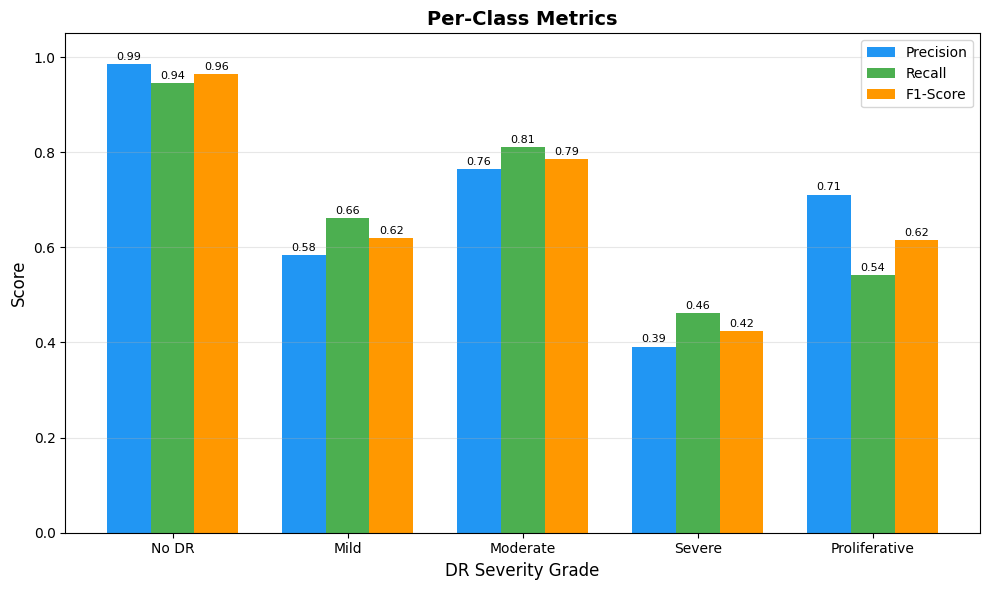

In [17]:
# ============================================================================
# 10. FINAL EVALUATION + METRICS VISUALIZATION
# ============================================================================
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

# --- Load best checkpoint ---
if os.path.exists(best_model_path):
    model.load_state_dict(
        torch.load(best_model_path, map_location=device, weights_only=False)
    )
    print("Best model loaded.")

# --- Evaluate ---
val_loss, val_acc, val_qwk, val_prec, val_rec, val_f1, y_true, y_pred = evaluate(
    model, val_loader, criterion, device
)

print(f"Final Val Loss: {val_loss:.4f}")
print(f"Final Val Acc : {val_acc:.4f}")
print(f"Final Val QWK : {val_qwk:.4f}")
print(f"Final Val Prec: {val_prec:.4f}")
print(f"Final Val Rec : {val_rec:.4f}")
print(f"Final Val F1  : {val_f1:.4f}")

print("\nClassification report:")
class_names = ["No DR", "Mild", "Moderate", "Severe", "Proliferative"]
print(classification_report(y_true, y_pred, target_names=class_names, digits=4))

# --- Save training history ---
history_path = os.path.join(CHECKPOINT_DIR, "training_history.csv")
hist_df = pd.DataFrame(history)
hist_df.to_csv(history_path, index=False)
print("Saved history to:", history_path)

# ============================================================================
# PLOT 1: Training Curves (2×2 grid)
# ============================================================================
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle("Training History", fontsize=16, fontweight="bold")

epochs_range = hist_df["epoch"]

# Train Loss
axes[0, 0].plot(
    epochs_range, hist_df["train_loss"], "b-o", markersize=4, label="Train Loss"
)
axes[0, 0].set_title("Training Loss")
axes[0, 0].set_xlabel("Epoch")
axes[0, 0].set_ylabel("Loss")
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)

# Val Loss
axes[0, 1].plot(
    epochs_range, hist_df["val_loss"], "r-o", markersize=4, label="Val Loss"
)
axes[0, 1].set_title("Validation Loss")
axes[0, 1].set_xlabel("Epoch")
axes[0, 1].set_ylabel("Loss")
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)

# Val Accuracy
axes[1, 0].plot(
    epochs_range, hist_df["val_acc"], "g-o", markersize=4, label="Val Accuracy"
)
axes[1, 0].set_title("Validation Accuracy")
axes[1, 0].set_xlabel("Epoch")
axes[1, 0].set_ylabel("Accuracy")
axes[1, 0].legend()
axes[1, 0].grid(True, alpha=0.3)

# Val QWK
axes[1, 1].plot(epochs_range, hist_df["val_qwk"], "m-o", markersize=4, label="Val QWK")
axes[1, 1].set_title("Validation Quadratic Weighted Kappa")
axes[1, 1].set_xlabel("Epoch")
axes[1, 1].set_ylabel("QWK")
axes[1, 1].legend()
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(
    os.path.join(CHECKPOINT_DIR, "training_curves.png"), dpi=150, bbox_inches="tight"
)
plt.show()

# ============================================================================
# PLOT 2: Confusion Matrix
# ============================================================================
cm = confusion_matrix(y_true, y_pred)
fig, ax = plt.subplots(figsize=(8, 7))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names,
    ax=ax,
    cbar_kws={"label": "Count"},
)
ax.set_title("Confusion Matrix", fontsize=14, fontweight="bold")
ax.set_xlabel("Predicted Label", fontsize=12)
ax.set_ylabel("True Label", fontsize=12)
plt.tight_layout()
plt.savefig(
    os.path.join(CHECKPOINT_DIR, "confusion_matrix.png"), dpi=150, bbox_inches="tight"
)
plt.show()

# ============================================================================
# PLOT 3: Per-Class Precision / Recall / F1
# ============================================================================
from sklearn.metrics import precision_recall_fscore_support as prfs

prec_per, rec_per, f1_per, sup_per = prfs(y_true, y_pred, average=None, zero_division=0)

x_pos = np.arange(len(class_names))
width = 0.25

fig, ax = plt.subplots(figsize=(10, 6))
bars1 = ax.bar(x_pos - width, prec_per, width, label="Precision", color="#2196F3")
bars2 = ax.bar(x_pos, rec_per, width, label="Recall", color="#4CAF50")
bars3 = ax.bar(x_pos + width, f1_per, width, label="F1-Score", color="#FF9800")

ax.set_xlabel("DR Severity Grade", fontsize=12)
ax.set_ylabel("Score", fontsize=12)
ax.set_title("Per-Class Metrics", fontsize=14, fontweight="bold")
ax.set_xticks(x_pos)
ax.set_xticklabels(class_names)
ax.set_ylim(0, 1.05)
ax.legend()
ax.grid(True, alpha=0.3, axis="y")

# Add value labels on bars
for bars in [bars1, bars2, bars3]:
    for bar in bars:
        height = bar.get_height()
        ax.annotate(
            f"{height:.2f}",
            xy=(bar.get_x() + bar.get_width() / 2, height),
            xytext=(0, 3),
            textcoords="offset points",
            ha="center",
            fontsize=8,
        )

plt.tight_layout()
plt.savefig(
    os.path.join(CHECKPOINT_DIR, "per_class_metrics.png"), dpi=150, bbox_inches="tight"
)
plt.show()

In [18]:
# ============================================================================
# 11. EXPORT TEACHER MODEL TO ONNX  (server-side reference only)
# ============================================================================
# Install onnx and onnxruntime if not already installed in runtime
!pip install -q onnx onnxruntime

import os
import torch
import torch.onnx

# Ensure model is in eval mode and on CPU for export
model.eval()
model_cpu = model.cpu()

# Create dummy input matching model input: (1, 3, 384, 384)
dummy_input = torch.randn(1, 3, 384, 384)

# Export path
onnx_path = os.path.join(CHECKPOINT_DIR, "swin_cbam_dr_model.onnx")

# Export to ONNX (using classic TorchScript exporter via dynamo=False)
export_kwargs = dict(
    export_params=True,
    opset_version=14,
    do_constant_folding=True,
    input_names=["input"],
    output_names=["output"],
    dynamic_axes={"input": {0: "batch_size"}, "output": {0: "batch_size"}},
)

print(f"Exporting model to {onnx_path}...")
try:
    torch.onnx.export(model_cpu, dummy_input, onnx_path, dynamo=False, **export_kwargs)
except TypeError:
    torch.onnx.export(model_cpu, dummy_input, onnx_path, **export_kwargs)

print(f"ONNX model exported to: {onnx_path}")
print(f"ONNX file size: {os.path.getsize(onnx_path) / (1024 * 1024):.2f} MB")

# --- Verify the ONNX model loads correctly ---
try:
    import onnxruntime as ort

    session = ort.InferenceSession(onnx_path, providers=["CPUExecutionProvider"])
    test_input = dummy_input.numpy()
    ort_outputs = session.run(None, {"input": test_input})
    print(f"ONNX verification passed. Output shape: {ort_outputs[0].shape}")
    print(f"Sample output logits: {ort_outputs[0][0]}")
except Exception as e:
    print(f"ONNX verification error: {e}")

# Move model back to GPU for subsequent cells
model.to(device)
print("Done! Model exported successfully.")


Exporting model to /content/drive/MyDrive/DR_Project/checkpoints/swin_cbam_dr_model.onnx...


/tmp/ipykernel_74078/2054514506.py:33: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(model_cpu, dummy_input, onnx_path, dynamo=False, **export_kwargs)
/usr/local/lib/python3.13/dist-packages/torch/__init__.py:2254: TracerWarning: Converting a tensor to a Python boolean might cause the trace to be incorrect. We can't record the data flow of Python values, so this value will be treated as a constant in the future. This means that the trace might not generalize to other inputs!
  if not condition:
/tmp/ipykernel_74078/3022009642.py:135: TracerWarning: Converting a tensor to a Python boolean might cause the trace to be incorrect. We can't rec

ONNX model exported to: /content/drive/MyDrive/DR_Project/checkpoints/swin_cbam_dr_model.onnx
ONNX file size: 373.34 MB
ONNX verification passed. Output shape: (1, 5)
Sample output logits: [ 0.0985442   0.05457548 -0.19613622 -1.270917    0.47825032]
Done! Model exported successfully.


In [19]:
# ============================================================================
# 12. STUDENT MODEL — MobileNetV3-Large + Lightweight CBAM  (Phase C)
# ============================================================================
# The edge model that runs on the Raspberry Pi 4 (PDF section 4.6.4, Figure 2).
#
#   Input (3×224×224) → MobileNetV3-Large backbone → (B, 960, 7, 7)
#   → Lightweight CBAM → Global Average Pool → FC(960 → 5) → logits
#
# Differences from the teacher (all taken from the PDF):
#   • Input is 224×224 (teacher: 384×384) to cut compute on the Pi.
#   • MobileNetV3 uses depthwise-separable convs + Hard-Swish (ARM-friendly).
#   • Lightweight CBAM:
#       channel attention : 960 → 40 → 960   (24× bottleneck vs 16× in teacher)
#       spatial attention : depthwise 7×7 conv + 1×1 pointwise conv
#         (teacher uses a single dense 7×7 conv)
#   • Head is just GAP → one FC layer (teacher: LN → FC512 → GELU → FC5).
#
# The student accepts the SAME 384×384 normalised batches as the teacher and
# resizes them to 224×224 inside forward() — so one DataLoader can feed both
# models during distillation and the existing evaluate() works unchanged.
# For deployment the ONNX graph takes 224×224 directly (see section 16).
# ============================================================================

STUDENT_MODEL_NAME = "mobilenetv3_large_100.ra_in1k"  # ImageNet-1k pretrained
STUDENT_IMG_SIZE = 224


class LiteCBAM(CBAM):
    """Lightweight CBAM for the edge student.

    Reuses CBAM.forward() (channel attention then spatial attention) and only
    swaps the two parameter-heavy parts for cheaper versions:
      - channel MLP bottleneck: 960 // 24 = 40 hidden units
      - spatial conv: depthwise 7×7 (one filter per input map) → 1×1 pointwise
    """

    def __init__(self, channels=960, reduction=24, spatial_kernel=7):
        super().__init__(channels, reduction, spatial_kernel)
        self.spatial = nn.Sequential(
            nn.Conv2d(
                2, 2, spatial_kernel, padding=spatial_kernel // 2, groups=2, bias=False
            ),  # depthwise 7×7 over the [avg, max] maps
            nn.Conv2d(2, 1, kernel_size=1, bias=False),  # pointwise 1×1 → 1 map
        )


class StudentMobileNet(nn.Module):
    """MobileNetV3-Large + LiteCBAM + single FC classifier (≈3M params)."""

    def __init__(self, num_classes=5, pretrained=True):
        super().__init__()
        # num_classes=0 / global_pool="" → keep the (B, 960, 7, 7) feature map
        self.backbone = timm.create_model(
            STUDENT_MODEL_NAME, pretrained=pretrained, num_classes=0, global_pool=""
        )
        # timm keeps the 960→1280 "conv_head" for its own classifier path, but
        # forward_features() never uses it. Drop it so the parameter count (and
        # checkpoint size) reflect only what the student actually runs.
        self.backbone.conv_head = nn.Identity()
        self.cbam = LiteCBAM(channels=960)
        self.fc = nn.Linear(960, num_classes)

    def forward_native(self, x, return_feat=False):
        """x: (B, 3, 224, 224), already ImageNet-normalised."""
        feat = self.backbone.forward_features(x)  # (B, 960, 7, 7)
        pooled_backbone = feat.mean(dim=(2, 3))  # (B, 960) — used for feature mimicking
        feat = self.cbam(feat)
        logits = self.fc(F.adaptive_avg_pool2d(feat, 1).flatten(1))
        return (logits, pooled_backbone) if return_feat else logits

    def forward(self, x, return_feat=False):
        # Teacher-resolution batches (384) are downsampled on the fly.
        if x.shape[-2:] != (STUDENT_IMG_SIZE, STUDENT_IMG_SIZE):
            x = F.interpolate(
                x,
                size=(STUDENT_IMG_SIZE, STUDENT_IMG_SIZE),
                mode="bilinear",
                align_corners=False,
                antialias=True,
            )
        return self.forward_native(x, return_feat)


student = StudentMobileNet(num_classes=5).to(device)

n_student = sum(p.numel() for p in student.parameters())
n_teacher = sum(p.numel() for p in model.parameters())
print(
    f"Student parameters: {n_student / 1e6:.2f} M   (teacher: {n_teacher / 1e6:.1f} M)"
)
print(
    f"  backbone : {sum(p.numel() for p in student.backbone.parameters()) / 1e6:.2f} M"
)
print(f"  LiteCBAM : {sum(p.numel() for p in student.cbam.parameters()):,}")
print(f"  FC head  : {sum(p.numel() for p in student.fc.parameters()):,}")


Student parameters: 3.05 M   (teacher: 87.5 M)
  backbone : 2.97 M
  LiteCBAM : 76,900
  FC head  : 4,805


In [ ]:
# ============================================================================
# 13. DISTILLATION UTILITIES — loss, teacher features, OCS metric  (Phase B)
# ============================================================================
# Ordinal-preserving knowledge distillation (PDF section 4.6.3):
#
#   L_total = 0.7 · T² · KL( softmax(z_T / T) ‖ softmax(z_S / T) )   soft labels
#           + 0.3 · CE( z_S, y )                                    hard labels
#           + 0.1 · MSE( proj(f_T), f_S )                           feature mimic
#
#   T = 4. The T² factor restores the gradient magnitude lost by softening.
#   f_T: teacher's pooled backbone features (1024-d), f_S: student's pooled
#   backbone features (960-d). A learnable Linear(1024 → 960) "projector" maps
#   teacher features into the student's space; it is trained jointly and
#   discarded after distillation (it is never exported).
# ============================================================================

KD_TEMPERATURE = 4.0
KD_W_SOFT, KD_W_HARD, KD_W_FEAT = 0.7, 0.3, 0.1


def teacher_forward(teacher, x):
    """Teacher forward that also returns its pooled backbone features.

    Mirrors SwinTeacher.forward() exactly (the class itself only returns
    logits), so teacher logits are identical to normal inference.
    Returns: logits (B, 5), pooled backbone features (B, 1024).
    """
    feat = teacher.backbone.forward_features(x)  # (B, 12, 12, 1024) NHWC
    if feat.dim() == 4 and feat.shape[-1] == 1024:
        feat = feat.permute(0, 3, 1, 2).contiguous()  # → (B, 1024, 12, 12)
    pooled = feat.mean(dim=(2, 3))  # feature-mimicking target (before CBAM)
    logits = teacher.head(teacher.cbam(feat))
    return logits, pooled


def distillation_loss(s_logits, t_logits, y, s_feat, t_feat_proj, T=KD_TEMPERATURE):
    """Composite KD loss. Returns (total, soft, hard, feat) — all float32."""
    s_logits, t_logits = s_logits.float(), t_logits.float()  # stable under AMP
    soft = (
        F.kl_div(
            F.log_softmax(s_logits / T, dim=1),
            F.softmax(t_logits / T, dim=1),
            reduction="batchmean",
        )
        * T
        * T
    )
    hard = F.cross_entropy(s_logits, y)
    feat = F.mse_loss(t_feat_proj.float(), s_feat.float())
    total = KD_W_SOFT * soft + KD_W_HARD * hard + KD_W_FEAT * feat
    return total, soft, hard, feat


def ordinal_consistency_score(logits):
    """Ordinal Consistency Score (OCS) — per-sample, in [0, 1].

    For a predicted distribution p over the K ordered grades, take the peak
    k = argmax(p). Moving AWAY from k in either direction, probability should
    never increase:  p[0] ≤ … ≤ p[k]  and  p[k] ≥ … ≥ p[K-1].
    OCS = fraction of the K-1 adjacent grade pairs that obey this.
    1.0 = perfectly unimodal (e.g. for true grade 3: P(2) and P(4) > P(0) and P(1)).

    Only the ORDER of the probabilities matters, so OCS is identical for any
    softmax temperature.
    """
    p = F.softmax(logits.float(), dim=1)  # (N, K)
    K = p.size(1)
    k = p.argmax(dim=1, keepdim=True)  # (N, 1) peak grade
    diff = p[:, :-1] - p[:, 1:]  # (N, K-1): p[i] - p[i+1]
    pair_idx = torch.arange(K - 1, device=p.device).unsqueeze(0)  # pair (i, i+1)
    right_of_peak = pair_idx >= k  # pairs at/after the peak must fall
    ok = torch.where(right_of_peak, diff >= 0, diff <= 0)  # left of peak must rise
    return ok.float().mean(dim=1)


In [21]:
# ============================================================================
# 14. DISTILLATION TRAINING — Swin teacher → MobileNetV3 student  (Phase B)
# ============================================================================
# Hyper-parameters from PDF section 4.6.3: 50 epochs, AdamW (lr 1e-3,
# weight-decay 1e-4), cosine annealing down to 1e-6, batch size 32, teacher
# frozen throughout. Model selection / early stopping use validation QWK,
# same as the teacher.
#
# Like the teacher loop, a full-state checkpoint is written every epoch, so a
# Colab disconnect just resumes from the last finished epoch.
# ============================================================================
from torch.optim.lr_scheduler import CosineAnnealingLR

STUDENT_EPOCHS = 50
STUDENT_LR = 1e-3
STUDENT_MIN_LR = 1e-6
STUDENT_WEIGHT_DECAY = 1e-4
STUDENT_BATCH_SIZE = 32
STUDENT_PATIENCE = 10  # early stopping on val QWK (same rule as the teacher)
# 1.0 = the PDF's single LR for everything. If the student underperforms,
# try 0.1 to fine-tune the pretrained backbone more gently than CBAM/FC.
STUDENT_BACKBONE_LR_MULT = 1.0

student_best_path = os.path.join(CHECKPOINT_DIR, "student_best.pth")
student_ckpt_path = os.path.join(CHECKPOINT_DIR, "student_latest_checkpoint.pth")

# --- Teacher: load the best Swin+CBAM weights and freeze --------------------
teacher = model  # SwinTeacher built in section 6
if os.path.exists(best_model_path):
    teacher.load_state_dict(
        torch.load(best_model_path, map_location=device, weights_only=False)
    )
    print(f"Teacher weights loaded from {best_model_path}")
else:
    print(
        "WARNING: best teacher checkpoint not found — distilling from current weights!"
    )
teacher.to(device).eval()
for p in teacher.parameters():
    p.requires_grad = False

# --- Loaders: same train/val data and class-balanced sampler, batch 32 -------
kd_train_loader = DataLoader(
    train_dataset,
    batch_size=STUDENT_BATCH_SIZE,
    sampler=sampler,
    num_workers=0,
    pin_memory=True,
)
kd_val_loader = DataLoader(
    val_dataset, batch_size=16, shuffle=False, num_workers=0, pin_memory=True
)

# --- Fail-fast: distilling from a poor teacher is pointless ------------------
ce_criterion = nn.CrossEntropyLoss()
_, t_acc, t_qwk, *_ = evaluate(teacher, kd_val_loader, ce_criterion, device)
print(f"Teacher on validation set: acc={t_acc:.4f}  QWK={t_qwk:.4f}")

# --- Projector (1024 → 960), trained jointly, discarded after distillation ---
projector = nn.Linear(1024, 960).to(device)

# --- Optimizer / scheduler / AMP scaler --------------------------------------
student_optimizer = torch.optim.AdamW(
    [
        {
            "params": student.backbone.parameters(),
            "lr": STUDENT_LR * STUDENT_BACKBONE_LR_MULT,
        },
        {
            "params": list(student.cbam.parameters())
            + list(student.fc.parameters())
            + list(projector.parameters()),
            "lr": STUDENT_LR,
        },
    ],
    weight_decay=STUDENT_WEIGHT_DECAY,
)
student_scheduler = CosineAnnealingLR(
    student_optimizer, T_max=STUDENT_EPOCHS, eta_min=STUDENT_MIN_LR
)
student_scaler = torch.amp.GradScaler("cuda")
trainable_params = list(student.parameters()) + list(projector.parameters())

# --- Resume ------------------------------------------------------------------
RESUME_STUDENT = True
student_start_epoch, student_best_qwk, student_patience_ctr = 0, 0.0, 0
student_history = []
if RESUME_STUDENT and os.path.exists(student_ckpt_path):
    ck = torch.load(student_ckpt_path, map_location=device, weights_only=False)
    student.load_state_dict(ck["student"])
    projector.load_state_dict(ck["projector"])
    student_optimizer.load_state_dict(ck["optimizer"])
    student_scheduler.load_state_dict(ck["scheduler"])
    student_scaler.load_state_dict(ck["scaler"])
    student_start_epoch = ck["epoch"] + 1
    student_best_qwk = ck["best_qwk"]
    student_patience_ctr = ck["patience_counter"]
    student_history = ck["history"]
    print(
        f"Resuming student at epoch {student_start_epoch + 1}/{STUDENT_EPOCHS} | "
        f"best QWK so far {student_best_qwk:.4f}"
    )
else:
    print("Starting student distillation from epoch 1.")

# --- Distillation loop -------------------------------------------------------
for epoch in range(student_start_epoch, STUDENT_EPOCHS):
    student.train()  # teacher stays in eval()
    sums = {"loss": 0.0, "soft": 0.0, "hard": 0.0, "feat": 0.0}
    n_seen = 0

    pbar = tqdm(
        kd_train_loader, desc=f"Distill {epoch + 1}/{STUDENT_EPOCHS}", leave=False
    )
    for images, labels in pbar:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        # Teacher: soft labels + pooled features (no gradients, 384×384 input)
        with torch.no_grad(), torch.amp.autocast("cuda"):
            t_logits, t_feat = teacher_forward(teacher, images)

        student_optimizer.zero_grad(set_to_none=True)
        with torch.amp.autocast("cuda"):
            # student() downsamples the 384 batch to 224 internally
            s_logits, s_feat = student(images, return_feat=True)
            loss, soft, hard, feat = distillation_loss(
                s_logits, t_logits, labels, s_feat, projector(t_feat)
            )

        student_scaler.scale(loss).backward()
        student_scaler.unscale_(student_optimizer)
        torch.nn.utils.clip_grad_norm_(trainable_params, max_norm=1.0)
        student_scaler.step(student_optimizer)
        student_scaler.update()

        bs = images.size(0)
        n_seen += bs
        for name, value in zip(sums, (loss, soft, hard, feat)):
            sums[name] += value.item() * bs
        pbar.set_postfix(loss=f"{loss.item():.4f}")

    student_scheduler.step()

    # --- Validation (hard labels, student only) ---
    v_loss, v_acc, v_qwk, v_prec, v_rec, v_f1, _, _ = evaluate(
        student, kd_val_loader, ce_criterion, device
    )
    row = {
        "epoch": epoch + 1,
        **{f"train_{k}": v / n_seen for k, v in sums.items()},
        "val_loss": v_loss,
        "val_acc": v_acc,
        "val_qwk": v_qwk,
        "val_prec": v_prec,
        "val_rec": v_rec,
        "val_f1": v_f1,
    }
    student_history.append(row)
    print(
        f"Epoch {epoch + 1:03d} | loss={row['train_loss']:.4f} "
        f"(soft={row['train_soft']:.3f} hard={row['train_hard']:.3f} "
        f"feat={row['train_feat']:.3f}) | val_acc={v_acc:.4f} | val_qwk={v_qwk:.4f} "
        f"| f1={v_f1:.4f} | lr={student_scheduler.get_last_lr()[-1]:.2e}"
    )

    if v_qwk > student_best_qwk + MIN_DELTA:
        student_best_qwk = v_qwk
        student_patience_ctr = 0
        torch.save(student.state_dict(), student_best_path)  # student only
        print(f"  Best student saved | QWK={v_qwk:.4f}  acc={v_acc:.4f}")
    else:
        student_patience_ctr += 1
        print(f"  No improvement. Patience: {student_patience_ctr}/{STUDENT_PATIENCE}")

    torch.save(
        {
            "epoch": epoch,
            "student": student.state_dict(),
            "projector": projector.state_dict(),
            "optimizer": student_optimizer.state_dict(),
            "scheduler": student_scheduler.state_dict(),
            "scaler": student_scaler.state_dict(),
            "best_qwk": student_best_qwk,
            "patience_counter": student_patience_ctr,
            "history": student_history,
        },
        student_ckpt_path,
    )

    if student_patience_ctr >= STUDENT_PATIENCE:
        print("Early stopping triggered.")
        break

# --- Keep the best weights; save the history -----------------------------------
if os.path.exists(student_best_path):
    student.load_state_dict(
        torch.load(student_best_path, map_location=device, weights_only=False)
    )
pd.DataFrame(student_history).to_csv(
    os.path.join(CHECKPOINT_DIR, "student_training_history.csv"), index=False
)
print(f"\nDistillation finished. Best student val QWK = {student_best_qwk:.4f}")


Teacher weights loaded from /content/drive/MyDrive/DR_Project/checkpoints/best_model.pth
Teacher on validation set: acc=0.8213  QWK=0.9043
Resuming student at epoch 20/50 | best QWK so far 0.9033


Distill 20/50:   0%|          | 0/226 [00:00<?, ?it/s]

Epoch 020 | loss=0.2505 (soft=0.189 hard=0.387 feat=0.020) | val_acc=0.8199 | val_qwk=0.8976 | f1=0.6633 | lr=6.55e-04
  No improvement. Patience: 14/10
Early stopping triggered.

Distillation finished. Best student val QWK = 0.9033


                                 model  params (M)  accuracy  precision  recall     f1    QWK    OCS
                Teacher: Swin-B + CBAM     87.5392    0.8213     0.6871  0.6841 0.6820 0.9043 0.7954
Student: MobileNetV3-L + LiteCBAM (KD)      3.0537    0.8145     0.6818  0.6582 0.6628 0.9033 0.7950

Student classification report:
               precision    recall  f1-score   support

        No DR     0.9913    0.9474    0.9688       361
         Mild     0.5349    0.6216    0.5750        74
     Moderate     0.7387    0.8200    0.7773       200
       Severe     0.3810    0.4103    0.3951        39
Proliferative     0.7632    0.4915    0.5979        59

     accuracy                         0.8145       733
    macro avg     0.6818    0.6582    0.6628       733
 weighted avg     0.8255    0.8145    0.8164       733



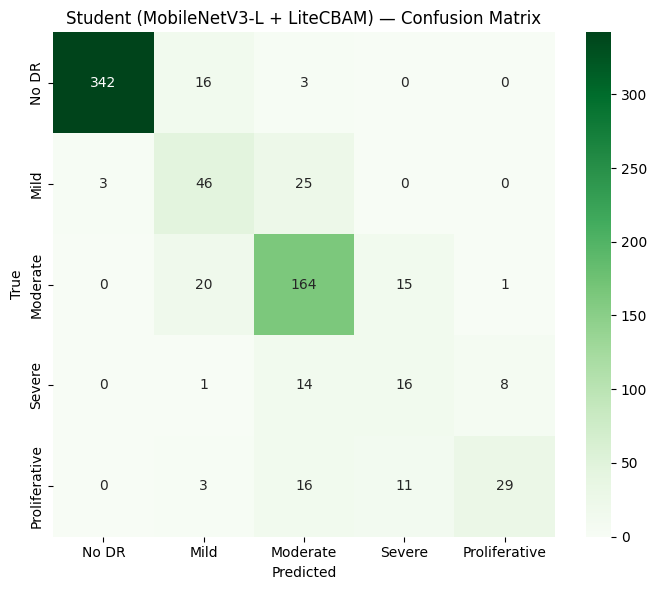

In [22]:
# ============================================================================
# 15. STUDENT EVALUATION — teacher vs. distilled student + OCS
# ============================================================================
# Compares the two models on the validation set: accuracy, macro precision /
# recall / F1, QWK, size, and the Ordinal Consistency Score (OCS) from
# section 13 — which tests whether the ordinal structure of the teacher's soft
# labels actually survives distillation (PDF targets: teacher OCS > 0.85,
# student OCS > 0.75).
# ============================================================================
import seaborn as sns
from sklearn.metrics import confusion_matrix

if os.path.exists(student_best_path):
    student.load_state_dict(
        torch.load(student_best_path, map_location=device, weights_only=False)
    )
student.eval()
teacher.eval()


@torch.no_grad()
def predict_logits(m, loader):
    """Run `m` over `loader` → (logits [N, 5] float32 on CPU, labels [N])."""
    m.eval()
    all_logits, all_labels = [], []
    for images, y in loader:
        with torch.amp.autocast("cuda", enabled=(device.type == "cuda")):
            out = m(images.to(device, non_blocking=True))
        all_logits.append(out.float().cpu())
        all_labels.append(y)
    return torch.cat(all_logits), torch.cat(all_labels).numpy()


student_class_names = ["No DR", "Mild", "Moderate", "Severe", "Proliferative"]
rows, student_preds = [], None
for name, m in [
    ("Teacher: Swin-B + CBAM", teacher),
    ("Student: MobileNetV3-L + LiteCBAM (KD)", student),
]:
    logits, y_true = predict_logits(m, kd_val_loader)
    y_pred = logits.argmax(1).numpy()
    prec, rec, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average="macro", zero_division=0
    )
    rows.append(
        {
            "model": name,
            "params (M)": sum(p.numel() for p in m.parameters()) / 1e6,
            "accuracy": accuracy_score(y_true, y_pred),
            "precision": prec,
            "recall": rec,
            "f1": f1,
            "QWK": cohen_kappa_score(y_true, y_pred, weights="quadratic"),
            "OCS": ordinal_consistency_score(logits).mean().item(),
        }
    )
    if m is student:
        student_preds = y_pred

print(pd.DataFrame(rows).to_string(index=False, float_format=lambda v: f"{v:.4f}"))

print("\nStudent classification report:")
print(
    classification_report(
        y_true,
        student_preds,
        target_names=student_class_names,
        digits=4,
        zero_division=0,
    )
)

fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(
    confusion_matrix(y_true, student_preds),
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=student_class_names,
    yticklabels=student_class_names,
    ax=ax,
)
ax.set_title("Student (MobileNetV3-L + LiteCBAM) — Confusion Matrix")
ax.set_xlabel("Predicted")
ax.set_ylabel("True")
plt.tight_layout()
plt.savefig(os.path.join(CHECKPOINT_DIR, "student_confusion_matrix.png"), dpi=150)
plt.show()


In [23]:
# ============================================================================
# 16. EXPORT STUDENT TO ONNX (FP32)  (Phase D, step 1)
# ============================================================================
# The deployable model is the distilled MobileNetV3 student — NOT the Swin
# teacher (that one is section 11, server-side reference only).
#
# Deployment contract of the exported graph:
#   input  "input"  : float32 RGB, shape (N, 3, 224, 224), values in [0, 1]
#   output "logits" : float32, shape (N, 5)  → argmax = DR grade 0-4
# ImageNet mean/std normalisation is baked INTO the graph, so the Pi only has
# to preprocess → resize to 224 → divide by 255 (no separate mean/std step).
# ============================================================================
!pip install -q onnx onnxruntime

import copy
import onnx
import onnxruntime as ort

IMAGENET_MEAN = (0.485, 0.456, 0.406)  # must match val_tfms in section 4
IMAGENET_STD = (0.229, 0.224, 0.225)

STUDENT_ONNX_FP32 = os.path.join(CHECKPOINT_DIR, "student_mobilenetv3_cbam_fp32.onnx")


class StudentForDeploy(nn.Module):
    """Student with ImageNet normalisation baked in; input is [0, 1] at 224×224."""

    def __init__(self, student_model):
        super().__init__()
        self.student = student_model
        self.register_buffer("mean", torch.tensor(IMAGENET_MEAN).view(1, 3, 1, 1))
        self.register_buffer("std", torch.tensor(IMAGENET_STD).view(1, 3, 1, 1))

    def forward(self, x):
        return self.student.forward_native((x - self.mean) / self.std)


def to_deploy_input(x_norm):
    """Training-pipeline batch (normalised, 384) → deployment input ([0, 1], 224)."""
    x = F.interpolate(
        x_norm.float().cpu(),
        size=(STUDENT_IMG_SIZE, STUDENT_IMG_SIZE),
        mode="bilinear",
        align_corners=False,
        antialias=True,
    )
    mean = torch.tensor(IMAGENET_MEAN).view(1, 3, 1, 1)
    std = torch.tensor(IMAGENET_STD).view(1, 3, 1, 1)
    return (x * std + mean).clamp(0.0, 1.0)


deploy_model = StudentForDeploy(copy.deepcopy(student).cpu().eval()).eval()
dummy_input = torch.rand(1, 3, STUDENT_IMG_SIZE, STUDENT_IMG_SIZE)

export_kwargs = dict(
    export_params=True,
    opset_version=17,
    do_constant_folding=True,
    input_names=["input"],
    output_names=["logits"],
    dynamic_axes={"input": {0: "batch"}, "logits": {0: "batch"}},
)
try:
    # Newer PyTorch defaults to the dynamo exporter; the classic TorchScript
    # exporter is the safer choice for ONNX Runtime on ARM.
    torch.onnx.export(
        deploy_model, dummy_input, STUDENT_ONNX_FP32, dynamo=False, **export_kwargs
    )
except TypeError:  # older PyTorch without the `dynamo` argument
    torch.onnx.export(deploy_model, dummy_input, STUDENT_ONNX_FP32, **export_kwargs)

onnx.checker.check_model(onnx.load(STUDENT_ONNX_FP32))
print(f"Saved {STUDENT_ONNX_FP32}  ({os.path.getsize(STUDENT_ONNX_FP32) / 1e6:.2f} MB)")

# --- Parity check on REAL validation images: ONNX Runtime vs PyTorch ---------
sess_fp32 = ort.InferenceSession(STUDENT_ONNX_FP32, providers=["CPUExecutionProvider"])
real_batch, _ = next(iter(DataLoader(val_dataset, batch_size=16, shuffle=False)))
x_deploy = to_deploy_input(real_batch)
with torch.no_grad():
    ref_logits = deploy_model(x_deploy).numpy()
ort_logits = sess_fp32.run(None, {"input": x_deploy.numpy()})[0]
print(
    f"max |PyTorch − ONNX| logit difference : {np.abs(ref_logits - ort_logits).max():.2e}"
)
print(
    f"argmax agreement on {len(x_deploy)} real images   : "
    f"{(ref_logits.argmax(1) == ort_logits.argmax(1)).mean():.2%}"
)


/tmp/ipykernel_74078/4109064843.py:66: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(


Saved /content/drive/MyDrive/DR_Project/checkpoints/student_mobilenetv3_cbam_fp32.onnx  (12.21 MB)
max |PyTorch − ONNX| logit difference : 3.34e-06
argmax agreement on 16 real images   : 100.00%


In [24]:
# ============================================================================
# 17. INT8 POST-TRAINING QUANTISATION  (Phase D, step 2)
# ============================================================================
# PDF section 4.6.5: INT8 PTQ with a 200-image calibration set drawn from the
# training data, weights AND activations 32-bit float → 8-bit integer, run on
# the Pi 4 (Cortex-A72, NEON) with ONNX Runtime.
#
# Calibration set: 40 images per DR grade (5 × 40 = 200), so the rare severe
# grades contribute to the activation ranges instead of being swamped by
# grade 0. Images go through the same pipeline as deployment (normal
# preprocessing → 224 → [0, 1]).
# ============================================================================
from onnxruntime.quantization import (
    CalibrationDataReader,
    QuantFormat,
    QuantType,
    quantize_static,
)
from onnxruntime.quantization.shape_inference import quant_pre_process
import time

STUDENT_ONNX_PREP = STUDENT_ONNX_FP32.replace(".onnx", "_prep.onnx")
STUDENT_ONNX_INT8 = os.path.join(CHECKPOINT_DIR, "student_mobilenetv3_cbam_int8.onnx")

calib_df = train_df.groupby("diagnosis", group_keys=False).sample(n=40, random_state=42)
calib_dataset = APTOSDataset(calib_df, IMAGE_DIR, val_tfms)  # no augmentation
print(
    f"Calibration images: {len(calib_dataset)}  "
    f"(per grade 0-4: {calib_df['diagnosis'].value_counts().sort_index().tolist()})"
)


class FundusCalibrationReader(CalibrationDataReader):
    """Feeds the 200 calibration images to the quantiser, one at a time."""

    def __init__(self, dataset, input_name="input"):
        self.dataset, self.input_name, self.idx = dataset, input_name, 0

    def get_next(self):
        if self.idx >= len(self.dataset):
            return None
        x, _ = self.dataset[self.idx]
        self.idx += 1
        return {self.input_name: to_deploy_input(x.unsqueeze(0)).numpy()}


# Optional graph clean-up recommended before static quantisation
try:
    quant_pre_process(STUDENT_ONNX_FP32, STUDENT_ONNX_PREP, skip_symbolic_shape=True)
    quant_input = STUDENT_ONNX_PREP
except Exception as e:
    print(f"quant_pre_process skipped ({type(e).__name__}); quantising the raw export.")
    quant_input = STUDENT_ONNX_FP32

quantize_static(
    model_input=quant_input,
    model_output=STUDENT_ONNX_INT8,
    calibration_data_reader=FundusCalibrationReader(calib_dataset),
    quant_format=QuantFormat.QDQ,  # Q/DQ nodes: the format ORT's ARM kernels expect
    activation_type=QuantType.QUInt8,
    weight_type=QuantType.QInt8,
    per_channel=True,
)
fp32_mb = os.path.getsize(STUDENT_ONNX_FP32) / 1e6
int8_mb = os.path.getsize(STUDENT_ONNX_INT8) / 1e6
print(
    f"FP32 {fp32_mb:.2f} MB  →  INT8 {int8_mb:.2f} MB  ({fp32_mb / int8_mb:.1f}× smaller)"
)


# --- Accuracy and speed of FP32 vs INT8 on the validation set ----------------
def onnx_val_predictions(path):
    sess = ort.InferenceSession(path, providers=["CPUExecutionProvider"])
    preds, labels = [], []
    for images, y in kd_val_loader:
        out = sess.run(None, {"input": to_deploy_input(images).numpy()})[0]
        preds.extend(out.argmax(1).tolist())
        labels.extend(y.tolist())
    return np.array(preds), np.array(labels)


def onnx_latency_ms(path, runs=50, threads=1):
    """Mean single-image latency. NOTE: measured on THIS machine, not the Pi.
    On x86 (Colab) INT8 is often NOT faster than FP32; the INT8 speed-up comes
    from the Pi's ARM NEON kernels, so time the model on the Pi itself."""
    opts = ort.SessionOptions()
    opts.intra_op_num_threads = threads
    sess = ort.InferenceSession(path, opts, providers=["CPUExecutionProvider"])
    x = np.random.rand(1, 3, STUDENT_IMG_SIZE, STUDENT_IMG_SIZE).astype(np.float32)
    for _ in range(5):  # warm-up
        sess.run(None, {"input": x})
    t0 = time.perf_counter()
    for _ in range(runs):
        sess.run(None, {"input": x})
    return (time.perf_counter() - t0) / runs * 1000


fp32_preds, val_labels = onnx_val_predictions(STUDENT_ONNX_FP32)
int8_preds, _ = onnx_val_predictions(STUDENT_ONNX_INT8)
for tag, pr, path in [
    ("FP32", fp32_preds, STUDENT_ONNX_FP32),
    ("INT8", int8_preds, STUDENT_ONNX_INT8),
]:
    print(
        f"{tag}: acc={accuracy_score(val_labels, pr):.4f}  "
        f"QWK={cohen_kappa_score(val_labels, pr, weights='quadratic'):.4f}  "
        f"latency={onnx_latency_ms(path):.1f} ms/img (1 thread, this machine)"
    )
print(f"FP32↔INT8 prediction agreement: {(fp32_preds == int8_preds).mean():.2%}")

# ---------------------------------------------------------------------------
# Raspberry Pi 4 inference recipe (pip install onnxruntime opencv-python-headless)
# ---------------------------------------------------------------------------
#   sess = ort.InferenceSession("student_mobilenetv3_cbam_int8.onnx",
#                               providers=["CPUExecutionProvider"])
#   img = preprocess_fundus_image(path, size=384)         # SAME preprocessing as section 2
#   img = cv2.resize(img, (224, 224), interpolation=cv2.INTER_AREA)
#   x = (img.astype(np.float32) / 255.0).transpose(2, 0, 1)[None]   # RGB, [0,1], NCHW
#   grade = int(sess.run(None, {"input": x})[0].argmax())           # 0..4
# Preprocess at 384 THEN downsample, because that is what the student saw in
# training (the preprocessed PNGs are 384×384).


Calibration images: 200  (per grade 0-4: [40, 40, 40, 40, 40])
FP32 12.21 MB  →  INT8 3.55 MB  (3.4× smaller)
FP32: acc=0.8145  QWK=0.9033  latency=6.9 ms/img (1 thread, this machine)
INT8: acc=0.7844  QWK=0.8900  latency=10.6 ms/img (1 thread, this machine)
FP32↔INT8 prediction agreement: 89.50%


20 epochs | best val QWK = 0.9047 (acc 0.8131) at epoch 13


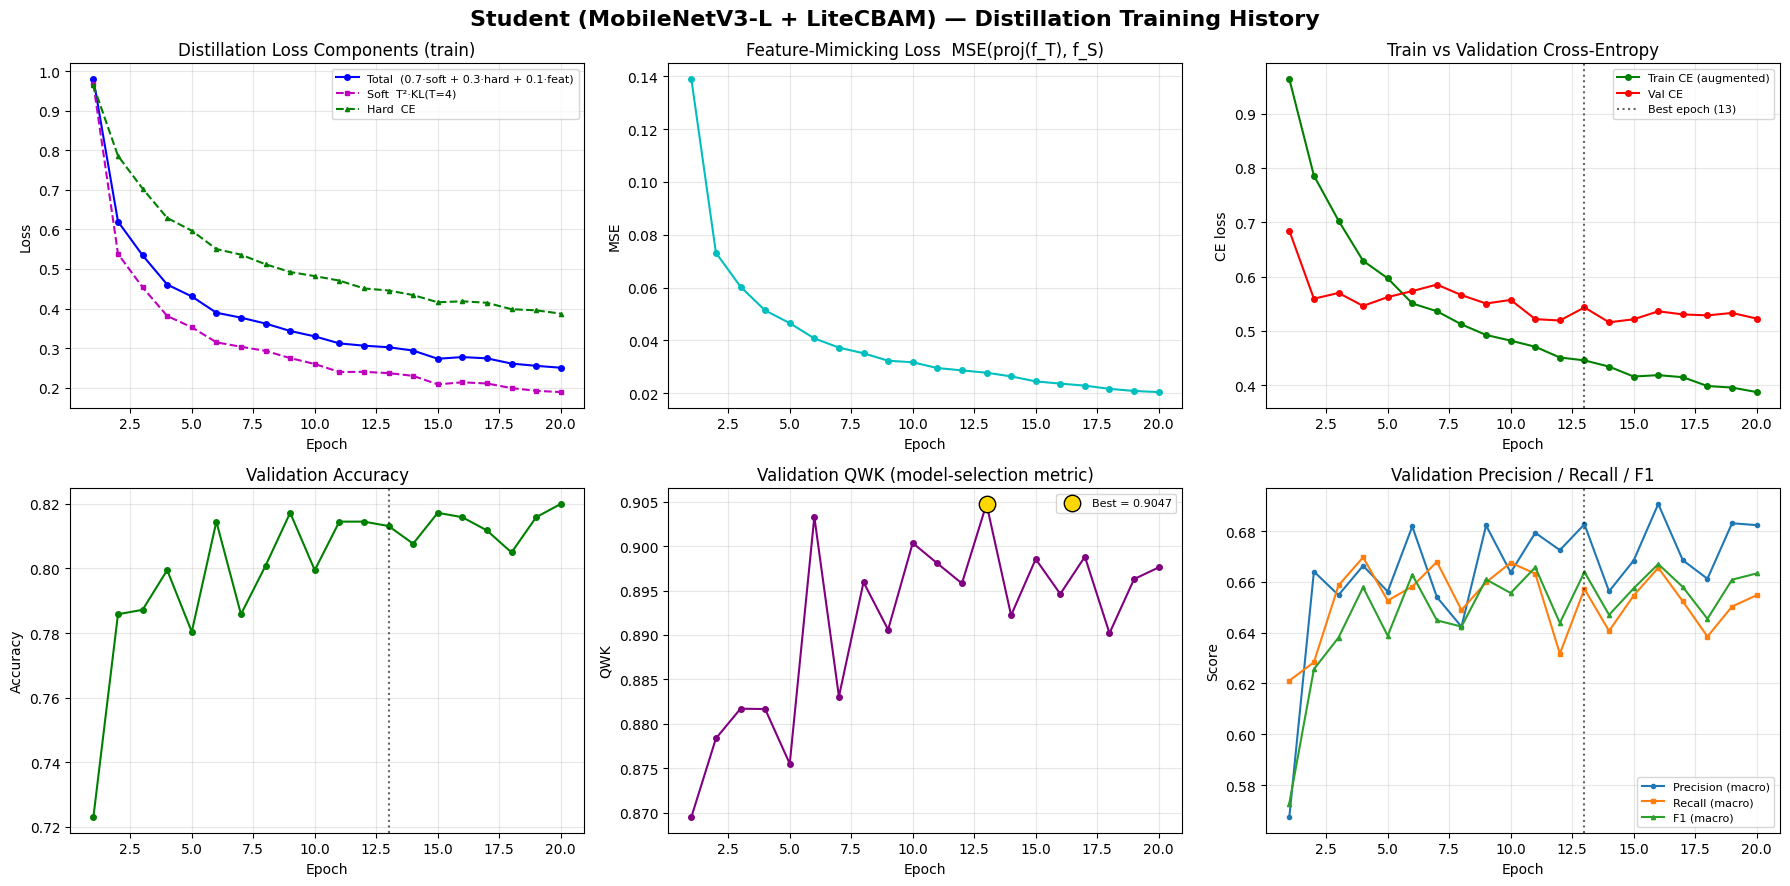

In [25]:
# ============================================================================
# 18. STUDENT TRAINING CURVES  (Phase B diagnostics)
# ============================================================================
# Plots the distillation history of the MobileNetV3 student: KD loss terms,
# train-vs-val cross-entropy (over-fitting check), accuracy, QWK and macro
# precision / recall / F1.  All figures are also saved to <checkpoints>/plots/.
# ============================================================================
import matplotlib.pyplot as plt
import seaborn as sns

PLOT_DIR = os.path.join(CHECKPOINT_DIR, "plots")
os.makedirs(PLOT_DIR, exist_ok=True)


def savefig(name):
    plt.savefig(os.path.join(PLOT_DIR, name), dpi=150, bbox_inches="tight")


# History lives in memory after the distillation cell; fall back to the CSV
# if the runtime was restarted.
try:
    sh = pd.DataFrame(student_history)
except NameError:
    sh = pd.DataFrame()
if sh.empty:
    sh = pd.read_csv(os.path.join(CHECKPOINT_DIR, "student_training_history.csv"))

ep = sh["epoch"]
best_i = sh["val_qwk"].idxmax()
best_ep = int(sh.loc[best_i, "epoch"])
print(
    f"{len(sh)} epochs | best val QWK = {sh.loc[best_i, 'val_qwk']:.4f} "
    f"(acc {sh.loc[best_i, 'val_acc']:.4f}) at epoch {best_ep}"
)

fig, axes = plt.subplots(2, 3, figsize=(18, 9))
fig.suptitle(
    "Student (MobileNetV3-L + LiteCBAM) — Distillation Training History",
    fontsize=16,
    fontweight="bold",
)

# (0,0) KD loss components (training)
ax = axes[0, 0]
ax.plot(
    ep, sh["train_loss"], "b-o", ms=4, label="Total  (0.7·soft + 0.3·hard + 0.1·feat)"
)
ax.plot(ep, sh["train_soft"], "m--s", ms=3, label="Soft  T²·KL(T=4)")
ax.plot(ep, sh["train_hard"], "g--^", ms=3, label="Hard  CE")
ax.set_title("Distillation Loss Components (train)")
ax.set_xlabel("Epoch")
ax.set_ylabel("Loss")
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3)

# (0,1) Feature-mimicking loss
ax = axes[0, 1]
ax.plot(ep, sh["train_feat"], "c-o", ms=4)
ax.set_title("Feature-Mimicking Loss  MSE(proj(f_T), f_S)")
ax.set_xlabel("Epoch")
ax.set_ylabel("MSE")
ax.grid(True, alpha=0.3)

# (0,2) Train CE vs Val CE -> over-fitting check
ax = axes[0, 2]
ax.plot(ep, sh["train_hard"], "g-o", ms=4, label="Train CE (augmented)")
ax.plot(ep, sh["val_loss"], "r-o", ms=4, label="Val CE")
ax.axvline(best_ep, color="k", ls=":", alpha=0.6, label=f"Best epoch ({best_ep})")
ax.set_title("Train vs Validation Cross-Entropy")
ax.set_xlabel("Epoch")
ax.set_ylabel("CE loss")
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3)

# (1,0) Val accuracy
ax = axes[1, 0]
ax.plot(ep, sh["val_acc"], "g-o", ms=4)
ax.axvline(best_ep, color="k", ls=":", alpha=0.6)
ax.set_title("Validation Accuracy")
ax.set_xlabel("Epoch")
ax.set_ylabel("Accuracy")
ax.grid(True, alpha=0.3)

# (1,1) Val QWK (early-stopping metric)
ax = axes[1, 1]
ax.plot(ep, sh["val_qwk"], "purple", marker="o", ms=4)
ax.scatter(
    [best_ep],
    [sh.loc[best_i, "val_qwk"]],
    s=140,
    c="gold",
    edgecolors="k",
    zorder=5,
    label=f"Best = {sh.loc[best_i, 'val_qwk']:.4f}",
)
ax.set_title("Validation QWK (model-selection metric)")
ax.set_xlabel("Epoch")
ax.set_ylabel("QWK")
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3)

# (1,2) Macro precision / recall / F1
ax = axes[1, 2]
ax.plot(ep, sh["val_prec"], "-o", ms=3, label="Precision (macro)")
ax.plot(ep, sh["val_rec"], "-s", ms=3, label="Recall (macro)")
ax.plot(ep, sh["val_f1"], "-^", ms=3, label="F1 (macro)")
ax.axvline(best_ep, color="k", ls=":", alpha=0.6)
ax.set_title("Validation Precision / Recall / F1")
ax.set_xlabel("Epoch")
ax.set_ylabel("Score")
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3)

plt.tight_layout()
savefig("student_training_curves.png")
plt.show()

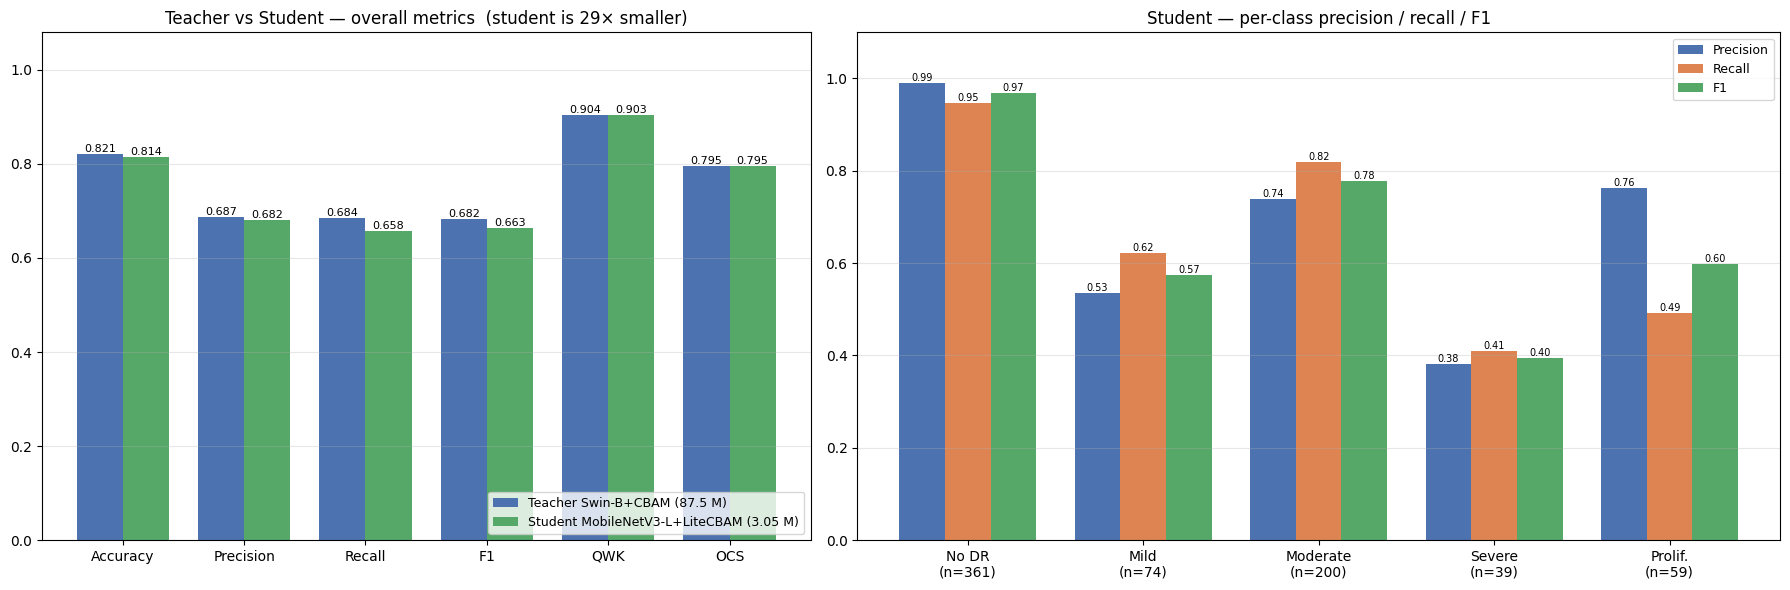

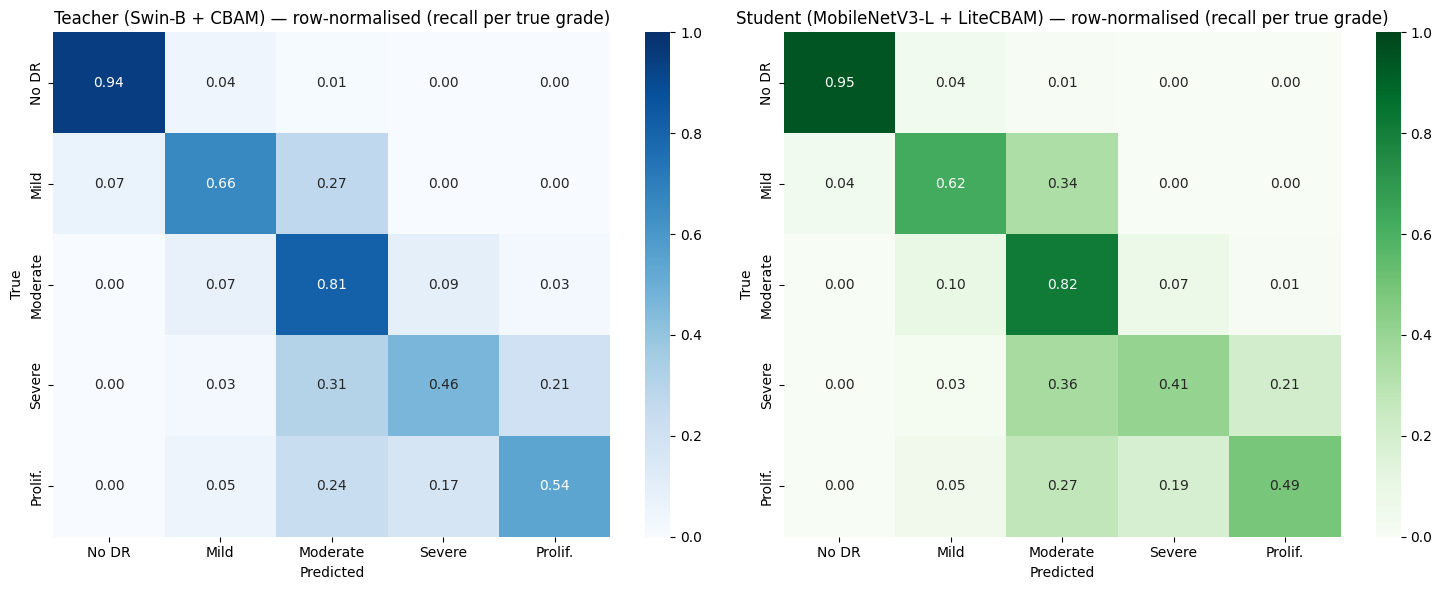

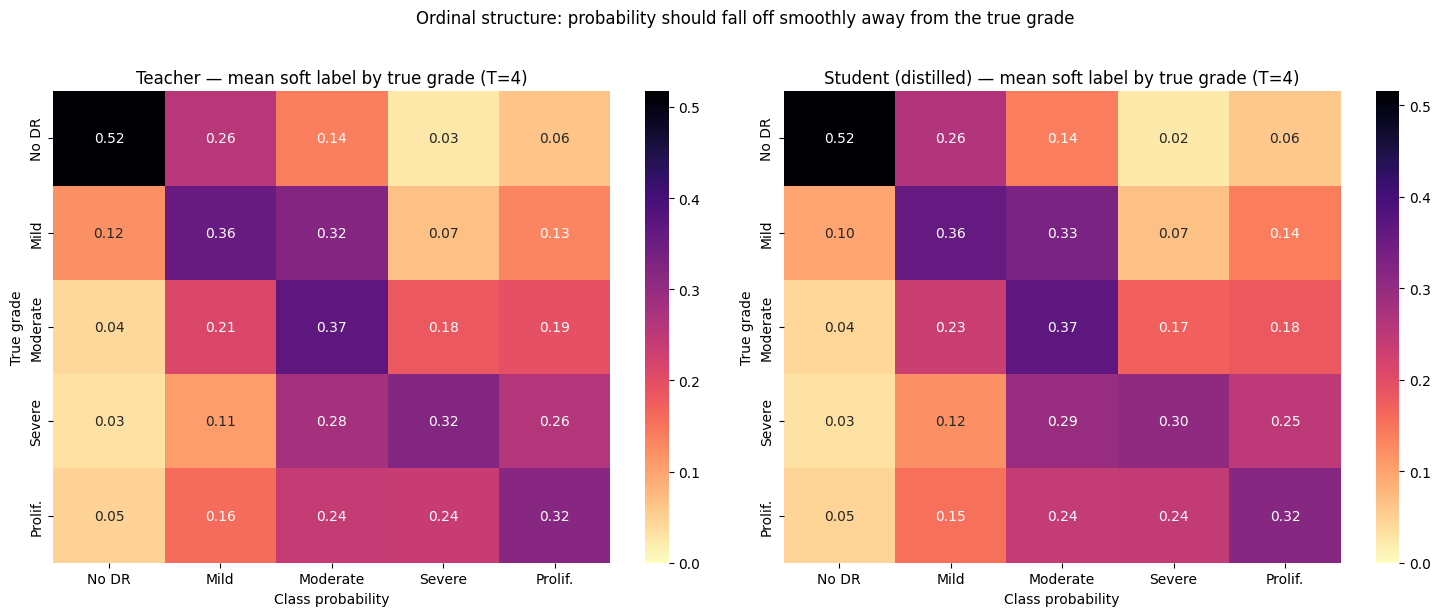

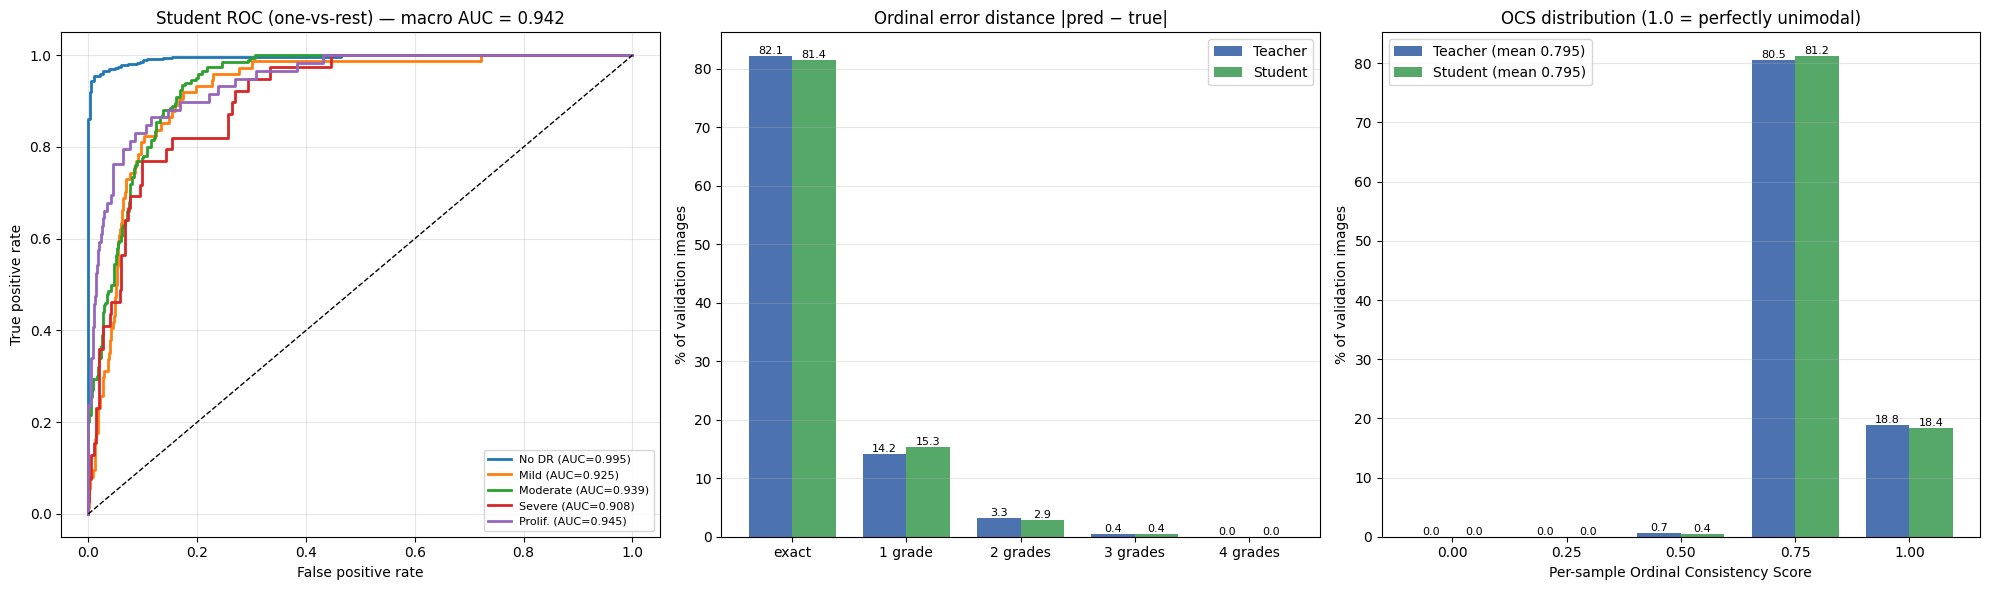

In [26]:
# ============================================================================
# 19. STUDENT vs TEACHER — evaluation graphs  (Phase B / C results)
# ============================================================================
#   Fig 1  metric comparison (teacher vs student) + student per-class P/R/F1
#   Fig 2  row-normalised confusion matrices (teacher | student)
#   Fig 3  mean soft-label distribution per true grade at T=4  (OCS story)
#   Fig 4  student ROC curves (one-vs-rest) | ordinal error distance | OCS
# ============================================================================
from sklearn.metrics import roc_curve, auc, roc_auc_score
from sklearn.preprocessing import label_binarize

K = 5
GRADES = ["No DR", "Mild", "Moderate", "Severe", "Prolif."]
student.eval()
teacher.eval()

t_logits, y_true = predict_logits(teacher, kd_val_loader)
s_logits, _ = predict_logits(student, kd_val_loader)
t_pred, s_pred = t_logits.argmax(1).numpy(), s_logits.argmax(1).numpy()


def summarise(logits, pred):
    p, r, f, _ = precision_recall_fscore_support(
        y_true, pred, average="macro", zero_division=0
    )
    return {
        "Accuracy": accuracy_score(y_true, pred),
        "Precision": p,
        "Recall": r,
        "F1": f,
        "QWK": cohen_kappa_score(y_true, pred, weights="quadratic"),
        "OCS": ordinal_consistency_score(logits).mean().item(),
    }


t_sum, s_sum = summarise(t_logits, t_pred), summarise(s_logits, s_pred)
n_t = sum(p.numel() for p in teacher.parameters()) / 1e6
n_s = sum(p.numel() for p in student.parameters()) / 1e6

# ---------------- Fig 1: metric comparison + per-class student metrics -------
fig, axes = plt.subplots(1, 2, figsize=(18, 6), gridspec_kw={"width_ratios": [1, 1.2]})

ax = axes[0]
metrics = list(t_sum)
x, w = np.arange(len(metrics)), 0.38
b1 = ax.bar(
    x - w / 2,
    [t_sum[m] for m in metrics],
    w,
    color="#4C72B0",
    label=f"Teacher Swin-B+CBAM ({n_t:.1f} M)",
)
b2 = ax.bar(
    x + w / 2,
    [s_sum[m] for m in metrics],
    w,
    color="#55A868",
    label=f"Student MobileNetV3-L+LiteCBAM ({n_s:.2f} M)",
)
ax.bar_label(b1, fmt="%.3f", fontsize=8)
ax.bar_label(b2, fmt="%.3f", fontsize=8)
ax.set_xticks(x)
ax.set_xticklabels(metrics)
ax.set_ylim(0, 1.08)
ax.set_title(
    f"Teacher vs Student — overall metrics  (student is {n_t / n_s:.0f}× smaller)"
)
ax.legend(loc="lower right", fontsize=9)
ax.grid(True, axis="y", alpha=0.3)

ax = axes[1]
p, r, f, sup = precision_recall_fscore_support(
    y_true, s_pred, labels=range(K), average=None, zero_division=0
)
x, w = np.arange(K), 0.26
for i, (vals, name, col) in enumerate(
    [(p, "Precision", "#4C72B0"), (r, "Recall", "#DD8452"), (f, "F1", "#55A868")]
):
    bars = ax.bar(x + (i - 1) * w, vals, w, label=name, color=col)
    ax.bar_label(bars, fmt="%.2f", fontsize=7)
ax.set_xticks(x)
ax.set_xticklabels([f"{g}\n(n={s})" for g, s in zip(GRADES, sup)])
ax.set_ylim(0, 1.1)
ax.set_title("Student — per-class precision / recall / F1")
ax.legend(fontsize=9)
ax.grid(True, axis="y", alpha=0.3)
plt.tight_layout()
savefig("student_metrics_comparison.png")
plt.show()

# ---------------- Fig 2: normalised confusion matrices -----------------------
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, pred, title, cmap in [
    (axes[0], t_pred, "Teacher (Swin-B + CBAM)", "Blues"),
    (axes[1], s_pred, "Student (MobileNetV3-L + LiteCBAM)", "Greens"),
]:
    cm = confusion_matrix(y_true, pred, labels=range(K), normalize="true")
    sns.heatmap(
        cm,
        annot=True,
        fmt=".2f",
        cmap=cmap,
        vmin=0,
        vmax=1,
        xticklabels=GRADES,
        yticklabels=GRADES,
        ax=ax,
    )
    ax.set_title(f"{title} — row-normalised (recall per true grade)")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")
plt.tight_layout()
savefig("student_confusion_normalised.png")
plt.show()

# ---------------- Fig 3: soft-label ordinal structure (T = 4) ----------------
T = KD_TEMPERATURE
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, logits, title in [
    (axes[0], t_logits, "Teacher"),
    (axes[1], s_logits, "Student (distilled)"),
]:
    soft = F.softmax(logits / T, dim=1).numpy()
    mean_soft = np.stack([soft[y_true == c].mean(0) for c in range(K)])
    sns.heatmap(
        mean_soft,
        annot=True,
        fmt=".2f",
        cmap="magma_r",
        vmin=0,
        xticklabels=GRADES,
        yticklabels=GRADES,
        ax=ax,
    )
    ax.set_title(f"{title} — mean soft label by true grade (T={T:g})")
    ax.set_xlabel("Class probability")
    ax.set_ylabel("True grade")
plt.suptitle(
    "Ordinal structure: probability should fall off smoothly away from the true grade",
    y=1.02,
    fontsize=12,
)
plt.tight_layout()
savefig("student_soft_label_heatmaps.png")
plt.show()

# ---------------- Fig 4: ROC | ordinal error distance | OCS ------------------
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

ax = axes[0]
probs = F.softmax(s_logits, dim=1).numpy()
y_bin = label_binarize(y_true, classes=range(K))
for c in range(K):
    fpr, tpr, _ = roc_curve(y_bin[:, c], probs[:, c])
    ax.plot(fpr, tpr, lw=2, label=f"{GRADES[c]} (AUC={auc(fpr, tpr):.3f})")
ax.plot([0, 1], [0, 1], "k--", lw=1)
macro_auc = roc_auc_score(y_bin, probs, average="macro")
ax.set_title(f"Student ROC (one-vs-rest) — macro AUC = {macro_auc:.3f}")
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.legend(fontsize=8, loc="lower right")
ax.grid(True, alpha=0.3)

ax = axes[1]
dist_t = np.bincount(np.abs(t_pred - y_true), minlength=K) / len(y_true) * 100
dist_s = np.bincount(np.abs(s_pred - y_true), minlength=K) / len(y_true) * 100
x, w = np.arange(K), 0.38
b1 = ax.bar(x - w / 2, dist_t, w, color="#4C72B0", label="Teacher")
b2 = ax.bar(x + w / 2, dist_s, w, color="#55A868", label="Student")
ax.bar_label(b1, fmt="%.1f", fontsize=8)
ax.bar_label(b2, fmt="%.1f", fontsize=8)
ax.set_xticks(x)
ax.set_xticklabels(
    [f"{d} grade{'s' if d != 1 else ''}" if d else "exact" for d in range(K)]
)
ax.set_ylabel("% of validation images")
ax.set_title("Ordinal error distance |pred − true|")
ax.legend()
ax.grid(True, axis="y", alpha=0.3)

ax = axes[2]
levels = np.linspace(0, 1, K)  # OCS takes values {0, .25, .5, .75, 1}
ocs_t = ordinal_consistency_score(t_logits).numpy()
ocs_s = ordinal_consistency_score(s_logits).numpy()
frac_t = [np.isclose(ocs_t, v).mean() * 100 for v in levels]
frac_s = [np.isclose(ocs_s, v).mean() * 100 for v in levels]
x = np.arange(K)
b1 = ax.bar(
    x - w / 2, frac_t, w, color="#4C72B0", label=f"Teacher (mean {ocs_t.mean():.3f})"
)
b2 = ax.bar(
    x + w / 2, frac_s, w, color="#55A868", label=f"Student (mean {ocs_s.mean():.3f})"
)
ax.bar_label(b1, fmt="%.1f", fontsize=8)
ax.bar_label(b2, fmt="%.1f", fontsize=8)
ax.set_xticks(x)
ax.set_xticklabels([f"{v:.2f}" for v in levels])
ax.set_xlabel("Per-sample Ordinal Consistency Score")
ax.set_ylabel("% of validation images")
ax.set_title("OCS distribution (1.0 = perfectly unimodal)")
ax.legend()
ax.grid(True, axis="y", alpha=0.3)
plt.tight_layout()
savefig("student_roc_error_ocs.png")
plt.show()

pd.DataFrame({"Teacher": t_sum, "Student": s_sum}).T.to_csv(
    os.path.join(CHECKPOINT_DIR, "teacher_vs_student_metrics.csv")
)

In [27]:
# ============================================================================
# 19b. RESTART-SAFE SETUP  (idempotent — safe to run any time)
# ============================================================================
# Colab kernels can die (RAM limit) or get recycled; every variable is then
# lost and later cells fail with NameError.  This cell rebuilds ONLY what the
# quantisation / deployment cells (sections 20-22) need — paths, validation
# data, ONNX helpers — and skips anything that already exists.  It does NOT
# need the Swin teacher or a GPU.  If the kernel restarts, run this cell and
# then jump straight to section 20/21/22.
# ============================================================================
import subprocess, sys

for _pkg, _imp in [
    ("onnx", "onnx"),
    ("onnxruntime", "onnxruntime"),
    ("albumentations", "albumentations"),
]:
    try:
        __import__(_imp)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", _pkg], check=True)

import os, gc, time, shutil, importlib
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import albumentations as A
from albumentations.pytorch import ToTensorV2
import onnx
import onnxruntime as ort
from onnxruntime.quantization import (
    CalibrationDataReader,
    CalibrationMethod,
    QuantFormat,
    QuantType,
    quantize_static,
)
from onnxruntime.quantization.shape_inference import quant_pre_process
from sklearn.metrics import (
    accuracy_score,
    cohen_kappa_score,
    confusion_matrix,
    precision_recall_fscore_support,
)

# ---- paths ---------------------------------------------------------------------
if "CHECKPOINT_DIR" not in globals():
    if not os.path.exists("/content/drive/MyDrive"):
        from google.colab import drive

        drive.mount("/content/drive")
    DATA_DIR = "/content/drive/MyDrive/DR_Project"
    RAW_DIR = f"{DATA_DIR}/APTOS"
    CHECKPOINT_DIR = f"{DATA_DIR}/checkpoints"
    IMAGE_DIR = f"{DATA_DIR}/preprocessed_images"
    TRAIN_SPLIT_CSV = f"{DATA_DIR}/train_split.csv"
    VAL_SPLIT_CSV = f"{DATA_DIR}/val_split.csv"
if "TRAIN_IMAGES_DIR" not in globals() or not os.path.exists(TRAIN_IMAGES_DIR):
    TRAIN_IMAGES_DIR = f"{RAW_DIR}/train_images"  # raw APTOS images

PLOT_DIR = os.path.join(CHECKPOINT_DIR, "plots")
os.makedirs(PLOT_DIR, exist_ok=True)

STUDENT_IMG_SIZE = globals().get("STUDENT_IMG_SIZE", 224)
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)
STUDENT_ONNX_FP32 = os.path.join(CHECKPOINT_DIR, "student_mobilenetv3_cbam_fp32.onnx")
STUDENT_ONNX_PREP = STUDENT_ONNX_FP32.replace(".onnx", "_prep.onnx")
STUDENT_ONNX_INT8 = os.path.join(CHECKPOINT_DIR, "student_mobilenetv3_cbam_int8.onnx")
quant_input = (
    STUDENT_ONNX_PREP if os.path.exists(STUDENT_ONNX_PREP) else STUDENT_ONNX_FP32
)
for _p in (STUDENT_ONNX_FP32, STUDENT_ONNX_INT8):
    assert os.path.exists(_p), f"Missing {_p} - run sections 16-17 first."

# ---- data ----------------------------------------------------------------------
if "train_df" not in globals():
    train_df = pd.read_csv(TRAIN_SPLIT_CSV)
if "val_df" not in globals():
    val_df = pd.read_csv(VAL_SPLIT_CSV)

if "val_tfms" not in globals():
    val_tfms = A.Compose(
        [A.Normalize(mean=list(IMAGENET_MEAN), std=list(IMAGENET_STD)), ToTensorV2()]
    )

if "APTOSDataset" not in globals():

    class APTOSDataset(Dataset):
        def __init__(self, dataframe, image_dir, transform=None):
            self.df = dataframe.reset_index(drop=True)
            self.image_dir, self.transform = image_dir, transform

        def __len__(self):
            return len(self.df)

        def __getitem__(self, idx):
            image_id = self.df.loc[idx, "id_code"]
            label = int(self.df.loc[idx, "diagnosis"])
            image = np.array(
                Image.open(os.path.join(self.image_dir, image_id + ".png")).convert(
                    "RGB"
                )
            )
            if self.transform:
                image = self.transform(image=image)["image"]
            return image, torch.tensor(label, dtype=torch.long)


if "val_dataset" not in globals():
    val_dataset = APTOSDataset(val_df, IMAGE_DIR, val_tfms)
if "kd_val_loader" not in globals():
    kd_val_loader = DataLoader(val_dataset, batch_size=16, shuffle=False, num_workers=0)

# ---- helpers -------------------------------------------------------------------
if "to_deploy_input" not in globals():

    def to_deploy_input(x_norm):
        """Training-pipeline batch (normalised, 384) -> deployment input ([0,1], 224)."""
        x = F.interpolate(
            x_norm.float().cpu(),
            size=(STUDENT_IMG_SIZE, STUDENT_IMG_SIZE),
            mode="bilinear",
            align_corners=False,
            antialias=True,
        )
        mean = torch.tensor(IMAGENET_MEAN).view(1, 3, 1, 1)
        std = torch.tensor(IMAGENET_STD).view(1, 3, 1, 1)
        return (x * std + mean).clamp(0.0, 1.0)


if "onnx_latency_ms" not in globals():

    def onnx_latency_ms(path, runs=50, threads=1):
        opts = ort.SessionOptions()
        opts.intra_op_num_threads = threads
        sess = ort.InferenceSession(path, opts, providers=["CPUExecutionProvider"])
        x = np.random.rand(1, 3, STUDENT_IMG_SIZE, STUDENT_IMG_SIZE).astype(np.float32)
        for _ in range(5):
            sess.run(None, {"input": x})
        t0 = time.perf_counter()
        for _ in range(runs):
            sess.run(None, {"input": x})
        return (time.perf_counter() - t0) / runs * 1000


if "ordinal_consistency_score" not in globals():

    def ordinal_consistency_score(logits):
        p = F.softmax(logits.float(), dim=1)
        K_ = p.size(1)
        k = p.argmax(dim=1, keepdim=True)
        diff = p[:, :-1] - p[:, 1:]
        pair_idx = torch.arange(K_ - 1, device=p.device).unsqueeze(0)
        ok = torch.where(pair_idx >= k, diff >= 0, diff <= 0)
        return ok.float().mean(dim=1)


if "savefig" not in globals():

    def savefig(name):
        plt.savefig(os.path.join(PLOT_DIR, name), dpi=150, bbox_inches="tight")


if "calib_df" not in globals():
    calib_df = train_df.groupby("diagnosis", group_keys=False).sample(
        n=40, random_state=42
    )
if "calib_dataset" not in globals():
    calib_dataset = APTOSDataset(calib_df, IMAGE_DIR, val_tfms)

if "FundusCalibrationReader" not in globals():

    class FundusCalibrationReader(CalibrationDataReader):
        def __init__(self, dataset, input_name="input"):
            self.dataset, self.input_name, self.idx = dataset, input_name, 0

        def get_next(self):
            if self.idx >= len(self.dataset):
                return None
            x, _ = self.dataset[self.idx]
            self.idx += 1
            return {self.input_name: to_deploy_input(x.unsqueeze(0)).numpy()}


def onnx_val_logits(path):
    """Run an ONNX model over the whole validation set -> (logits [N,5], labels [N])."""
    sess = ort.InferenceSession(path, providers=["CPUExecutionProvider"])
    outs, labels = [], []
    for images, y in kd_val_loader:
        outs.append(sess.run(None, {"input": to_deploy_input(images).numpy()})[0])
        labels.extend(y.tolist())
    return np.concatenate(outs), np.array(labels)


print("Setup OK")
print("  checkpoints :", CHECKPOINT_DIR)
print(
    "  raw images  :", TRAIN_IMAGES_DIR, "| exists:", os.path.exists(TRAIN_IMAGES_DIR)
)
print("  val images  :", len(val_df), "| quant_input:", os.path.basename(quant_input))

Setup OK
  checkpoints : /content/drive/MyDrive/DR_Project/checkpoints
  raw images  : /content/train_images | exists: True
  val images  : 733 | quant_input: student_mobilenetv3_cbam_fp32_prep.onnx


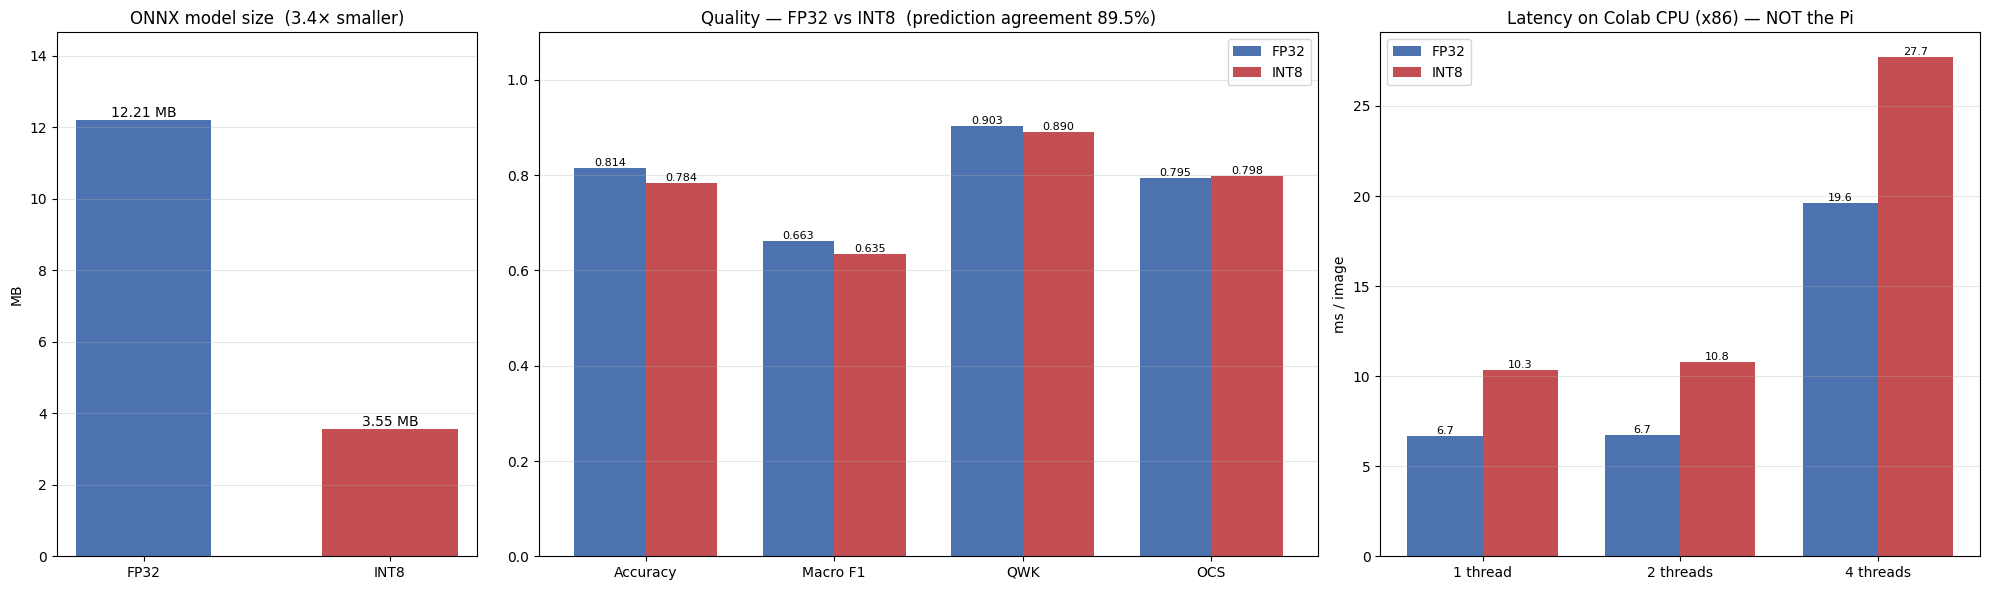

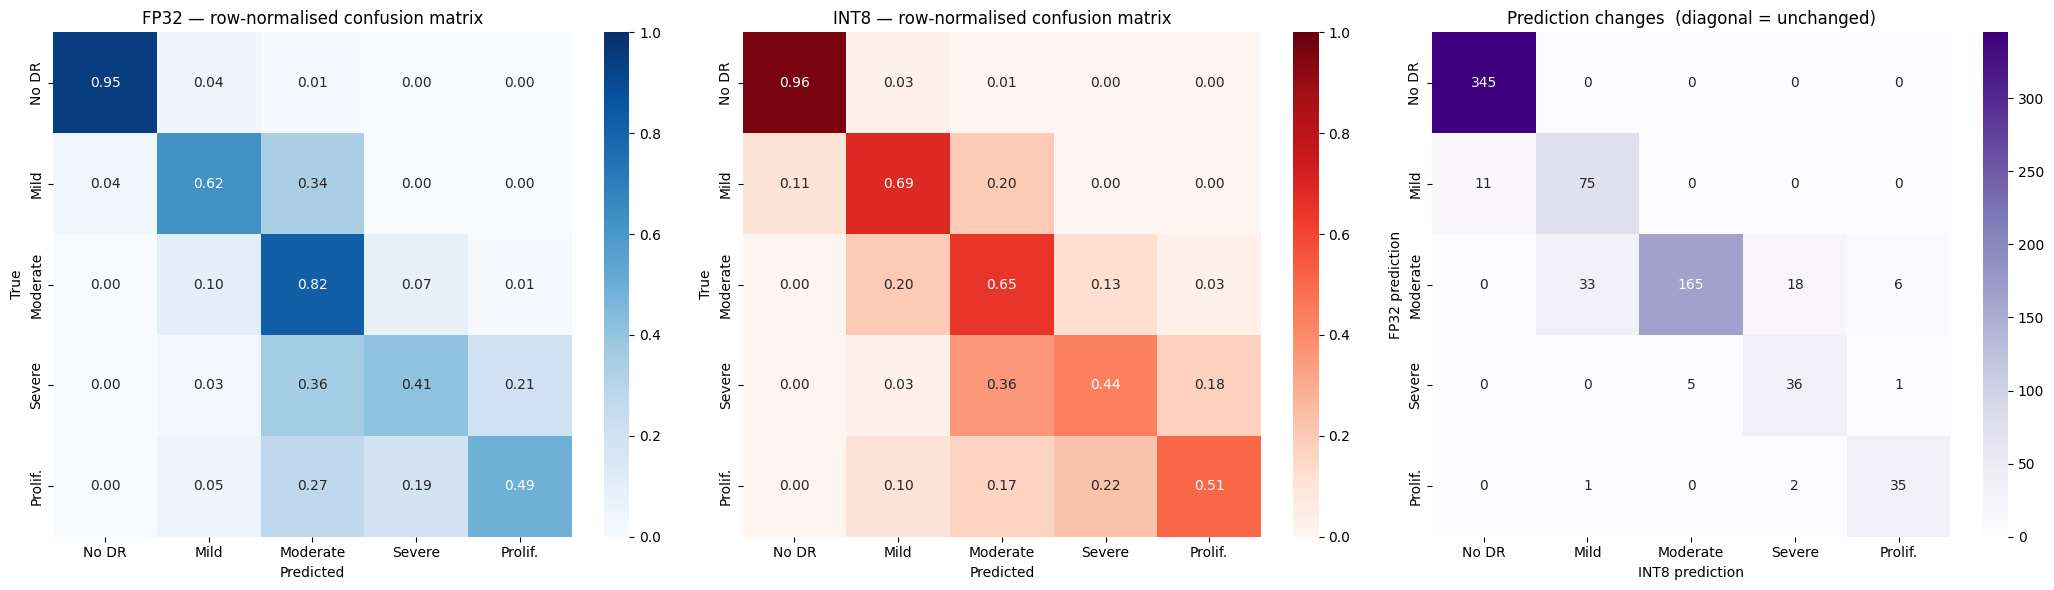

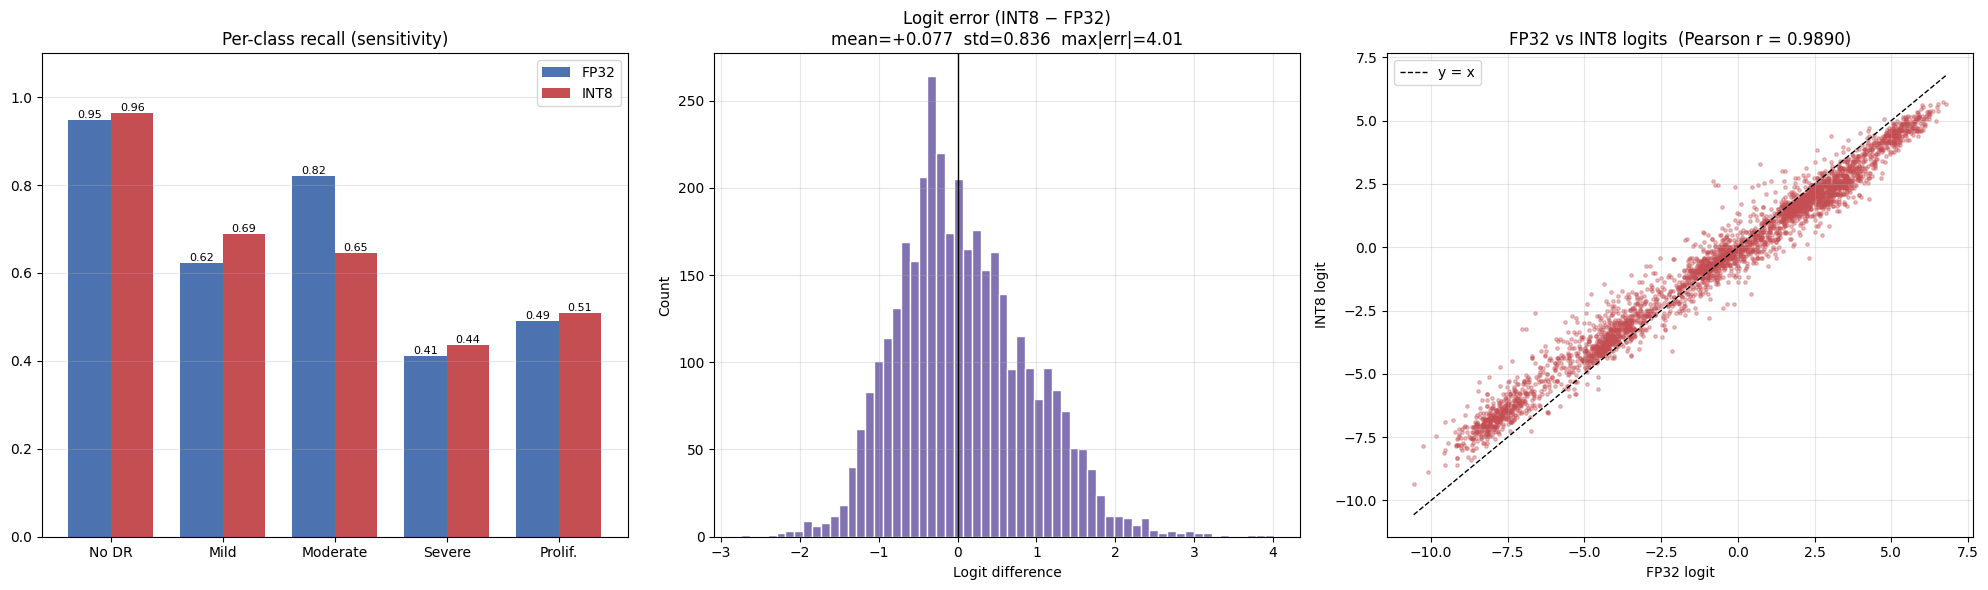

      Accuracy  Macro F1    QWK    OCS  size_MB  lat_ms_1thread_colab
FP32    0.8145    0.6628 0.9033 0.7950  12.2077                6.6718
INT8    0.7844    0.6355 0.8900 0.7981   3.5477               10.3480

NOTE: INT8 being slower than FP32 here is expected on x86 Colab. Measure FP32 vs INT8 on the Raspberry Pi itself (section 22) and ship whichever is faster / accurate enough.


In [28]:
# ============================================================================
# 20. INT8 QUANTISATION — graphs  (Phase D)
# ============================================================================
#   Fig 1  size | accuracy-QWK-F1-OCS (FP32 vs INT8) | latency
#   Fig 2  confusion matrices FP32 | INT8 | prediction flips FP32→INT8
#   Fig 3  per-class recall | logit-error histogram | FP32-vs-INT8 logit scatter
# Uses STUDENT_ONNX_FP32 / STUDENT_ONNX_INT8 from sections 16-17.
# ============================================================================
assert os.path.exists(STUDENT_ONNX_INT8), "Run section 17 first (INT8 model missing)."


def onnx_val_logits(path):
    """Run an ONNX model over the whole validation set -> (logits [N,5], labels [N])."""
    sess = ort.InferenceSession(path, providers=["CPUExecutionProvider"])
    outs, labels = [], []
    for images, y in kd_val_loader:
        outs.append(sess.run(None, {"input": to_deploy_input(images).numpy()})[0])
        labels.extend(y.tolist())
    return np.concatenate(outs), np.array(labels)


fp32_logits, yq = onnx_val_logits(STUDENT_ONNX_FP32)
int8_logits, _ = onnx_val_logits(STUDENT_ONNX_INT8)
fp32_pred, int8_pred = fp32_logits.argmax(1), int8_logits.argmax(1)
K = 5
GRADES = ["No DR", "Mild", "Moderate", "Severe", "Prolif."]


def q_summary(logits, pred):
    p, r, f, _ = precision_recall_fscore_support(
        yq, pred, average="macro", zero_division=0
    )
    return {
        "Accuracy": accuracy_score(yq, pred),
        "Macro F1": f,
        "QWK": cohen_kappa_score(yq, pred, weights="quadratic"),
        "OCS": ordinal_consistency_score(torch.from_numpy(logits)).mean().item(),
    }


fp32_sum, int8_sum = (
    q_summary(fp32_logits, fp32_pred),
    q_summary(int8_logits, int8_pred),
)
fp32_mb = os.path.getsize(STUDENT_ONNX_FP32) / 1e6
int8_mb = os.path.getsize(STUDENT_ONNX_INT8) / 1e6

# Latency on THIS machine (Colab x86). Not representative of the Pi — see note.
threads_list = [1, 2, 4]
lat_fp32 = [onnx_latency_ms(STUDENT_ONNX_FP32, threads=t) for t in threads_list]
lat_int8 = [onnx_latency_ms(STUDENT_ONNX_INT8, threads=t) for t in threads_list]

# ---------------- Fig 1 -------------------------------------------------------
fig, axes = plt.subplots(
    1, 3, figsize=(20, 6), gridspec_kw={"width_ratios": [0.7, 1.3, 1]}
)

ax = axes[0]
bars = ax.bar(
    ["FP32", "INT8"], [fp32_mb, int8_mb], color=["#4C72B0", "#C44E52"], width=0.55
)
ax.bar_label(bars, fmt="%.2f MB", fontsize=10)
ax.set_title(f"ONNX model size  ({fp32_mb / int8_mb:.1f}× smaller)")
ax.set_ylabel("MB")
ax.set_ylim(0, fp32_mb * 1.2)
ax.grid(True, axis="y", alpha=0.3)

ax = axes[1]
names = list(fp32_sum)
x, w = np.arange(len(names)), 0.38
b1 = ax.bar(x - w / 2, [fp32_sum[m] for m in names], w, color="#4C72B0", label="FP32")
b2 = ax.bar(x + w / 2, [int8_sum[m] for m in names], w, color="#C44E52", label="INT8")
ax.bar_label(b1, fmt="%.3f", fontsize=8)
ax.bar_label(b2, fmt="%.3f", fontsize=8)
ax.set_xticks(x)
ax.set_xticklabels(names)
ax.set_ylim(0, 1.1)
ax.set_title(
    f"Quality — FP32 vs INT8  (prediction agreement {np.mean(fp32_pred == int8_pred):.1%})"
)
ax.legend()
ax.grid(True, axis="y", alpha=0.3)

ax = axes[2]
x, w = np.arange(len(threads_list)), 0.38
b1 = ax.bar(x - w / 2, lat_fp32, w, color="#4C72B0", label="FP32")
b2 = ax.bar(x + w / 2, lat_int8, w, color="#C44E52", label="INT8")
ax.bar_label(b1, fmt="%.1f", fontsize=8)
ax.bar_label(b2, fmt="%.1f", fontsize=8)
ax.set_xticks(x)
ax.set_xticklabels([f"{t} thread{'s' if t > 1 else ''}" for t in threads_list])
ax.set_ylabel("ms / image")
ax.set_title("Latency on Colab CPU (x86) — NOT the Pi")
ax.legend()
ax.grid(True, axis="y", alpha=0.3)
plt.tight_layout()
savefig("quant_overview.png")
plt.show()

# ---------------- Fig 2: confusion matrices + flips ---------------------------
fig, axes = plt.subplots(1, 3, figsize=(21, 6))
for ax, pred, title, cmap in [
    (axes[0], fp32_pred, "FP32", "Blues"),
    (axes[1], int8_pred, "INT8", "Reds"),
]:
    cm = confusion_matrix(yq, pred, labels=range(K), normalize="true")
    sns.heatmap(
        cm,
        annot=True,
        fmt=".2f",
        cmap=cmap,
        vmin=0,
        vmax=1,
        xticklabels=GRADES,
        yticklabels=GRADES,
        ax=ax,
    )
    ax.set_title(f"{title} — row-normalised confusion matrix")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")
flip = confusion_matrix(fp32_pred, int8_pred, labels=range(K))
sns.heatmap(
    flip,
    annot=True,
    fmt="d",
    cmap="Purples",
    xticklabels=GRADES,
    yticklabels=GRADES,
    ax=axes[2],
)
axes[2].set_title("Prediction changes  (diagonal = unchanged)")
axes[2].set_xlabel("INT8 prediction")
axes[2].set_ylabel("FP32 prediction")
plt.tight_layout()
savefig("quant_confusion_and_flips.png")
plt.show()

# ---------------- Fig 3: per-class recall | logit error | scatter -------------
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

ax = axes[0]
rec32 = precision_recall_fscore_support(
    yq, fp32_pred, labels=range(K), average=None, zero_division=0
)[1]
rec8 = precision_recall_fscore_support(
    yq, int8_pred, labels=range(K), average=None, zero_division=0
)[1]
x, w = np.arange(K), 0.38
b1 = ax.bar(x - w / 2, rec32, w, color="#4C72B0", label="FP32")
b2 = ax.bar(x + w / 2, rec8, w, color="#C44E52", label="INT8")
ax.bar_label(b1, fmt="%.2f", fontsize=8)
ax.bar_label(b2, fmt="%.2f", fontsize=8)
ax.set_xticks(x)
ax.set_xticklabels(GRADES)
ax.set_ylim(0, 1.1)
ax.set_title("Per-class recall (sensitivity)")
ax.legend()
ax.grid(True, axis="y", alpha=0.3)

ax = axes[1]
err = (int8_logits - fp32_logits).ravel()
ax.hist(err, bins=60, color="#8172B2", edgecolor="white")
ax.axvline(0, color="k", lw=1)
ax.set_title(
    f"Logit error (INT8 − FP32)\nmean={err.mean():+.3f}  std={err.std():.3f}  max|err|={np.abs(err).max():.2f}"
)
ax.set_xlabel("Logit difference")
ax.set_ylabel("Count")
ax.grid(True, alpha=0.3)

ax = axes[2]
ax.scatter(fp32_logits.ravel(), int8_logits.ravel(), s=6, alpha=0.35, color="#C44E52")
lo = min(fp32_logits.min(), int8_logits.min())
hi = max(fp32_logits.max(), int8_logits.max())
ax.plot([lo, hi], [lo, hi], "k--", lw=1, label="y = x")
corr = np.corrcoef(fp32_logits.ravel(), int8_logits.ravel())[0, 1]
ax.set_title(f"FP32 vs INT8 logits  (Pearson r = {corr:.4f})")
ax.set_xlabel("FP32 logit")
ax.set_ylabel("INT8 logit")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
savefig("quant_logit_fidelity.png")
plt.show()

summary_df = pd.DataFrame({"FP32": fp32_sum, "INT8": int8_sum}).T
summary_df["size_MB"] = [fp32_mb, int8_mb]
summary_df["lat_ms_1thread_colab"] = [lat_fp32[0], lat_int8[0]]
print(summary_df.to_string(float_format=lambda v: f"{v:.4f}"))
summary_df.to_csv(os.path.join(CHECKPOINT_DIR, "quantisation_summary.csv"))
print(
    "\nNOTE: INT8 being slower than FP32 here is expected on x86 Colab. Measure "
    "FP32 vs INT8 on the Raspberry Pi itself (section 22) and ship whichever is "
    "faster / accurate enough."
)

Free RAM ≈ 7.9 GB -> histogram calibration on 25 images
[run]  MinMax + FC in FP32  (200 calibration images) ...
[ok]   MinMax + FC in FP32: acc=0.7885 QWK=0.8914
[run]  Percentile  (25 calibration images) ...
Finding optimal threshold for each tensor using 'percentile' algorithm ...
Number of tensors : 180
Number of histogram bins : 2048
Percentile : (0.0010000000000047748,99.999)
[ok]   Percentile: acc=0.7735 QWK=0.8823
[run]  Entropy  (25 calibration images) ...
Finding optimal threshold for each tensor using 'entropy' algorithm ...
Number of tensors : 180
Number of histogram bins : 128 (The number may increase depends on the data it collects)
Number of quantized bins : 128
[ok]   Entropy: acc=0.7776 QWK=0.8957

              variant  accuracy    QWK  macro_F1  agree_w_FP32  size_MB
     FP32 (reference)    0.8145 0.9033    0.6628        1.0000  12.2077
MinMax (current INT8)    0.7844 0.8900    0.6355        0.8950   3.5477
  MinMax + FC in FP32    0.7885 0.8914    0.6419        0.8

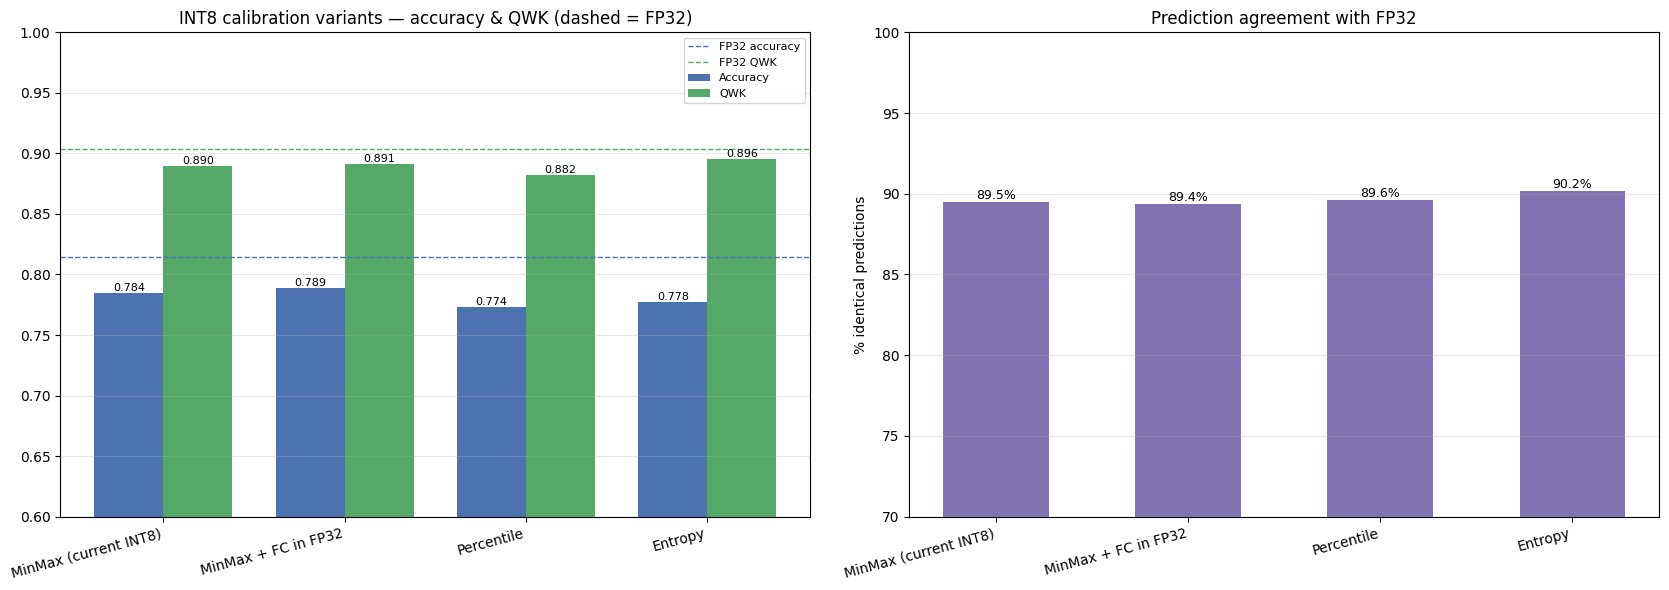


Best INT8 variant by QWK: Entropy  ->  DEPLOY_ONNX = /content/drive/MyDrive/DR_Project/checkpoints/student_int8_entropy.onnx


In [29]:
# ============================================================================
# 21. (OPTIONAL) INT8 CALIBRATION SWEEP — memory-safe & resumable
# ============================================================================
# Why the previous version crashed the kernel: ORT's Percentile / Entropy
# calibrators keep EVERY intermediate tensor of EVERY calibration image in RAM
# (~0.1 GB per image for MobileNetV3 at 224x224) -> 200 images ≈ 20 GB.
#
# This version:
#   * runs the cheap MinMax variant first (streaming, uses all 200 images),
#   * runs Percentile / Entropy on a RAM-sized subset (auto-chosen from the
#     memory actually free right now, 10-40 images),
#   * writes results to CSV after every variant and skips variants whose .onnx
#     already exists, so a crash never costs you finished work (just re-run).
# Needs section 19b (restart-safe setup) to have been run in this session.
# Set RUN_HISTOGRAM_VARIANTS = False to skip the two RAM-hungry variants.
# ============================================================================
import gc

RUN_SWEEP = True
RUN_HISTOGRAM_VARIANTS = True
PER_IMAGE_GB = 0.12  # rough RAM per calibration image for histogram calibrators

gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

if RUN_SWEEP:
    try:
        import psutil

        avail_gb = psutil.virtual_memory().available / 1e9
    except Exception:
        avail_gb = 6.0
    n_hist = int(min(40, max(10, avail_gb * 0.4 / PER_IMAGE_GB)))
    per_grade = max(2, n_hist // 5)
    print(
        f"Free RAM ≈ {avail_gb:.1f} GB -> histogram calibration on {per_grade * 5} images"
    )

    fc_nodes = [
        n.name
        for n in onnx.load(quant_input).graph.node
        if n.op_type in ("Gemm", "MatMul")
    ][-1:]  # the final classifier layer

    variants = [
        (
            "MinMax + FC in FP32",
            dict(calibrate_method=CalibrationMethod.MinMax, nodes_to_exclude=fc_nodes),
            calib_dataset,  # all 200 images (MinMax is streaming)
        )
    ]
    if RUN_HISTOGRAM_VARIANTS:
        calib_small = APTOSDataset(
            calib_df.groupby("diagnosis", group_keys=False).sample(
                n=min(per_grade, 40), random_state=42
            ),
            IMAGE_DIR,
            val_tfms,
        )
        variants += [
            (
                "Percentile",
                dict(calibrate_method=CalibrationMethod.Percentile),
                calib_small,
            ),
            ("Entropy", dict(calibrate_method=CalibrationMethod.Entropy), calib_small),
        ]

    # --- reference: FP32 and the INT8 model from section 17 -------------------------
    fp32_lg, yy_ref = onnx_val_logits(STUDENT_ONNX_FP32)
    fp32_ref = fp32_lg.argmax(1)
    sweep = {
        "FP32 (reference)": STUDENT_ONNX_FP32,
        "MinMax (current INT8)": STUDENT_ONNX_INT8,
    }
    sweep_csv = os.path.join(CHECKPOINT_DIR, "quantisation_sweep.csv")

    def evaluate_variant(name, path):
        lg, yy = onnx_val_logits(path)
        pr = lg.argmax(1)
        return {
            "variant": name,
            "accuracy": accuracy_score(yy, pr),
            "QWK": cohen_kappa_score(yy, pr, weights="quadratic"),
            "macro_F1": precision_recall_fscore_support(
                yy, pr, average="macro", zero_division=0
            )[2],
            "agree_w_FP32": float((pr == fp32_ref).mean()),
            "size_MB": os.path.getsize(path) / 1e6,
            "path": path,
        }

    rows = [evaluate_variant(n, p) for n, p in sweep.items()]

    for name, kw, calib_ds in variants:
        out_path = os.path.join(
            CHECKPOINT_DIR,
            "student_int8_"
            + name.lower().replace(" ", "_").replace("+", "and")
            + ".onnx",
        )
        try:
            if os.path.exists(out_path):
                print(
                    f"[skip] {name}: already quantised -> reusing {os.path.basename(out_path)}"
                )
            else:
                print(f"[run]  {name}  ({len(calib_ds)} calibration images) ...")
                quantize_static(
                    model_input=quant_input,
                    model_output=out_path,
                    calibration_data_reader=FundusCalibrationReader(calib_ds),
                    quant_format=QuantFormat.QDQ,
                    activation_type=QuantType.QUInt8,
                    weight_type=QuantType.QInt8,
                    per_channel=True,
                    **kw,
                )
            rows.append(evaluate_variant(name, out_path))
            print(
                f"[ok]   {name}: acc={rows[-1]['accuracy']:.4f} QWK={rows[-1]['QWK']:.4f}"
            )
        except Exception as e:
            print(f"[fail] {name}: {type(e).__name__}: {e}")
        pd.DataFrame(rows).to_csv(sweep_csv, index=False)  # save progress
        gc.collect()

    sweep_df = pd.DataFrame(rows)
    print()
    print(
        sweep_df.drop(columns="path").to_string(
            index=False, float_format=lambda v: f"{v:.4f}"
        )
    )

    # --- graph ---------------------------------------------------------------------
    fp32_row = sweep_df.iloc[0]
    q_df = sweep_df.iloc[1:].reset_index(drop=True)  # INT8 variants only
    fig, axes = plt.subplots(1, 2, figsize=(17, 6))
    x, w = np.arange(len(q_df)), 0.38
    ax = axes[0]
    b1 = ax.bar(x - w / 2, q_df["accuracy"], w, color="#4C72B0", label="Accuracy")
    b2 = ax.bar(x + w / 2, q_df["QWK"], w, color="#55A868", label="QWK")
    ax.axhline(
        fp32_row["accuracy"], color="#4C72B0", ls="--", lw=1, label="FP32 accuracy"
    )
    ax.axhline(fp32_row["QWK"], color="#55A868", ls="--", lw=1, label="FP32 QWK")
    ax.bar_label(b1, fmt="%.3f", fontsize=8)
    ax.bar_label(b2, fmt="%.3f", fontsize=8)
    ax.set_xticks(x)
    ax.set_xticklabels(q_df["variant"], rotation=15, ha="right")
    ax.set_ylim(0.6, 1.0)
    ax.set_title("INT8 calibration variants — accuracy & QWK (dashed = FP32)")
    ax.legend(fontsize=8)
    ax.grid(True, axis="y", alpha=0.3)

    ax = axes[1]
    b = ax.bar(x, q_df["agree_w_FP32"] * 100, color="#8172B2", width=0.55)
    ax.bar_label(b, fmt="%.1f%%", fontsize=9)
    ax.set_xticks(x)
    ax.set_xticklabels(q_df["variant"], rotation=15, ha="right")
    ax.set_ylim(70, 100)
    ax.set_ylabel("% identical predictions")
    ax.set_title("Prediction agreement with FP32")
    ax.grid(True, axis="y", alpha=0.3)
    plt.tight_layout()
    savefig("quant_calibration_sweep.png")
    plt.show()

    best = q_df.sort_values("QWK", ascending=False).iloc[0]
    DEPLOY_ONNX = best["path"]
    print(
        f"\nBest INT8 variant by QWK: {best['variant']}  ->  DEPLOY_ONNX = {DEPLOY_ONNX}"
    )

In [30]:
# ============================================================================
# 22. RASPBERRY PI 4 DEPLOYMENT PACKAGE  (Phase D, step 3)
# ============================================================================
# Builds <checkpoints>/pi_deploy/ and a zip you can download:
#     student_int8.onnx        <- the quantised model that runs on the Pi
#     student_fp32.onnx        <- for an FP32-vs-INT8 speed test on the Pi
#     pi_infer.py              <- standalone inference script (preprocess + ONNX)
#     samples/                 <- one raw fundus image per DR grade
#     README_PI.md             <- setup + run commands
# It also runs pi_infer.py's exact preprocessing here in Colab on 100 raw
# validation images to prove the deployment pipeline matches the notebook.
# ============================================================================
# Needs section 19b (restart-safe setup) to have been run in this session.
import shutil, sys, importlib, glob, subprocess

# DEPLOY_ONNX is set by section 21 (best calibration variant); otherwise the
# INT8 model from section 17 is shipped.
DEPLOY_ONNX = globals().get("DEPLOY_ONNX") or STUDENT_ONNX_INT8
PI_DIR = os.path.join(CHECKPOINT_DIR, "pi_deploy")
os.makedirs(os.path.join(PI_DIR, "samples"), exist_ok=True)

# ---- 1. sanity-check the model that will be shipped -------------------------
m = onnx.load(DEPLOY_ONNX)
onnx.checker.check_model(m)
print("Shipping model :", DEPLOY_ONNX)
print(f"Size           : {os.path.getsize(DEPLOY_ONNX) / 1e6:.2f} MB")
for t in m.graph.input:
    print(
        "Input          :",
        t.name,
        [d.dim_value or d.dim_param for d in t.type.tensor_type.shape.dim],
    )
for t in m.graph.output:
    print(
        "Output         :",
        t.name,
        [d.dim_value or d.dim_param for d in t.type.tensor_type.shape.dim],
    )
shutil.copy(DEPLOY_ONNX, os.path.join(PI_DIR, "student_int8.onnx"))
shutil.copy(STUDENT_ONNX_FP32, os.path.join(PI_DIR, "student_fp32.onnx"))

# ---- 2. the Pi inference script ----------------------------------------------
PI_SCRIPT = r'''#!/usr/bin/env python3
"""OpthaEdge-DED  -  Raspberry Pi 4 inference for the INT8 MobileNetV3+LiteCBAM student.

  python3 pi_infer.py samples/                       # run on a folder
  python3 pi_infer.py fundus.png --threads 4         # single image
  python3 pi_infer.py samples/ --benchmark 50        # latency
  python3 pi_infer.py --camera --model student_int8.onnx   # Pi camera (picamera2)

Model contract: input  float32 (N,3,224,224) RGB in [0,1]  (ImageNet mean/std baked in)
                output float32 (N,5) logits -> argmax = DR grade 0..4
"""
import argparse, glob, os, sys, time
import cv2
import numpy as np
import onnxruntime as ort

CLASS_NAMES = ["No DR", "Mild", "Moderate", "Severe", "Proliferative DR"]


# ---- preprocessing: IDENTICAL to the training notebook (section 2) ---------
def stage1_denoise(img, sigma=10, alpha=4, beta=-4, C=128):
    smoothed = cv2.GaussianBlur(img, (0, 0), sigma)
    return cv2.addWeighted(img, alpha, smoothed, beta, C)


def stage2_roi_selection(img):
    gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    _, mask = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    ys, xs = np.where(mask > 0)
    if len(xs) == 0 or len(ys) == 0:
        return img
    x0, y0, x1, y1 = xs.min(), ys.min(), xs.max(), ys.max()
    if x1 <= x0 or y1 <= y0:
        return img
    return img[y0:y1, x0:x1]


def preprocess_array(bgr):
    """BGR uint8 image -> (1,3,224,224) float32 in [0,1]."""
    img = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
    img = stage1_denoise(img)
    img = stage2_roi_selection(img)
    img = cv2.resize(img, (384, 384), interpolation=cv2.INTER_AREA)   # as in training PNGs
    img = cv2.resize(img, (224, 224), interpolation=cv2.INTER_AREA)   # student input size
    return (img.astype(np.float32) / 255.0).transpose(2, 0, 1)[None]


def preprocess(path):
    bgr = cv2.imread(path)
    if bgr is None:
        raise FileNotFoundError(path)
    return preprocess_array(bgr)


def load_session(model, threads=4):
    opts = ort.SessionOptions()
    opts.intra_op_num_threads = threads
    opts.graph_optimization_level = ort.GraphOptimizationLevel.ORT_ENABLE_ALL
    return ort.InferenceSession(model, opts, providers=["CPUExecutionProvider"])


def predict(sess, x):
    logits = sess.run(None, {"input": x})[0][0]
    p = np.exp(logits - logits.max())
    p /= p.sum()
    return int(p.argmax()), p


def capture_camera(path="capture.png"):
    from picamera2 import Picamera2          # sudo apt install python3-picamera2
    cam = Picamera2()
    cam.configure(cam.create_still_configuration())
    cam.start(); time.sleep(2)               # let exposure settle
    cam.capture_file(path); cam.stop()
    return path


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("inputs", nargs="*", help="image file(s) or folder(s)")
    ap.add_argument("--model", default="student_int8.onnx")
    ap.add_argument("--threads", type=int, default=4)
    ap.add_argument("--benchmark", type=int, default=0, help="N timed runs per model")
    ap.add_argument("--camera", action="store_true")
    a = ap.parse_args()

    files = []
    for p in a.inputs:
        files += sorted(glob.glob(os.path.join(p, "*"))) if os.path.isdir(p) else [p]
    if a.camera:
        files.append(capture_camera())
    files = [f for f in files if f.lower().endswith((".png", ".jpg", ".jpeg"))]

    sess = load_session(a.model, a.threads)
    print(f"model={a.model} threads={a.threads}")
    for f in files:
        t0 = time.perf_counter()
        x = preprocess(f)
        t1 = time.perf_counter()
        grade, p = predict(sess, x)
        t2 = time.perf_counter()
        print(f"{os.path.basename(f):32s} -> grade {grade} ({CLASS_NAMES[grade]})  "
              f"conf={p[grade]:.2f}  prep={1000*(t1-t0):.0f}ms  infer={1000*(t2-t1):.1f}ms")

    if a.benchmark and files:
        x = preprocess(files[0])
        for name in ("student_int8.onnx", "student_fp32.onnx"):
            if not os.path.exists(name):
                continue
            s = load_session(name, a.threads)
            for _ in range(5):
                s.run(None, {"input": x})
            t0 = time.perf_counter()
            for _ in range(a.benchmark):
                s.run(None, {"input": x})
            ms = (time.perf_counter() - t0) / a.benchmark * 1000
            print(f"benchmark {name:20s} {ms:7.1f} ms/img  ({a.threads} threads, model only)")


if __name__ == "__main__":
    main()
'''
with open(os.path.join(PI_DIR, "pi_infer.py"), "w") as fh:
    fh.write(PI_SCRIPT)


# ---- 3. sample raw images (one per grade) -------------------------------------
def find_raw(image_id):
    for ext in (".png", ".jpg", ".jpeg"):
        p = os.path.join(TRAIN_IMAGES_DIR, image_id + ext)
        if os.path.exists(p):
            return p
    return None


for g, row in val_df.groupby("diagnosis").head(1).iterrows():
    src = find_raw(row["id_code"])
    if src:
        shutil.copy(
            src,
            os.path.join(
                PI_DIR,
                "samples",
                f"grade{int(row['diagnosis'])}_{row['id_code']}{os.path.splitext(src)[1]}",
            ),
        )

# ---- 4. README -----------------------------------------------------------------
README = """# OpthaEdge-DED - Raspberry Pi 4 deployment

Requires 64-bit Raspberry Pi OS (aarch64) - ONNX Runtime has no 32-bit wheel on PyPI.
  uname -m        # must print aarch64

  python3 -m venv ~/ded && source ~/ded/bin/activate
  pip install onnxruntime numpy opencv-python-headless

  python3 pi_infer.py samples/                 # predictions
  python3 pi_infer.py samples/ --benchmark 50  # FP32 vs INT8 latency on the Pi

Pi camera (Module v2) - needs the system picamera2 package:
  sudo apt install -y python3-picamera2
  python3 -m venv --system-site-packages ~/ded   # recreate venv with system packages
  python3 pi_infer.py --camera
"""
with open(os.path.join(PI_DIR, "README_PI.md"), "w") as fh:
    fh.write(README)

# ---- 5. Colab-side parity test of the EXACT Pi code path -----------------------
sys.path.insert(0, PI_DIR)
import pi_infer

importlib.reload(pi_infer)
sess_pi = pi_infer.load_session(DEPLOY_ONNX, threads=2)
ref_logits, ref_labels = onnx_val_logits(DEPLOY_ONNX)  # notebook (PNG-based) pipeline
N_CHECK = 100
agree = correct = used = 0
for i, image_id in enumerate(val_df["id_code"].tolist()[:N_CHECK]):
    src = find_raw(image_id)
    if src is None:
        continue
    grade, _ = pi_infer.predict(sess_pi, pi_infer.preprocess(src))
    agree += int(grade == int(ref_logits[i].argmax()))
    correct += int(grade == int(ref_labels[i]))
    used += 1
print(
    f"\nPi-pipeline parity on {used} raw val images:\n"
    f"  same grade as notebook pipeline : {agree / used:.1%}\n"
    f"  accuracy vs ground truth        : {correct / used:.1%}"
)

print("\nSample predictions (run the same on the Pi and compare):")
_r = subprocess.run(
    [
        sys.executable,
        os.path.join(PI_DIR, "pi_infer.py"),
        os.path.join(PI_DIR, "samples"),
        "--model",
        os.path.join(PI_DIR, "student_int8.onnx"),
        "--threads",
        "2",
    ],
    capture_output=True,
    text=True,
)
print(_r.stdout or _r.stderr)

# ---- 6. zip + download ----------------------------------------------------------
zip_base = "/content/opthaedge_pi_deploy"
shutil.make_archive(zip_base, "zip", PI_DIR)
print(f"\nZip: {zip_base}.zip  ({os.path.getsize(zip_base + '.zip') / 1e6:.1f} MB)")
print(f"Also on Drive: {PI_DIR}")
try:
    from google.colab import files

    files.download(zip_base + ".zip")
except Exception as e:
    print("Auto-download skipped:", e)

Shipping model : /content/drive/MyDrive/DR_Project/checkpoints/student_int8_entropy.onnx
Size           : 3.55 MB
Input          : input ['batch', 3, 224, 224]
Output         : logits ['batch', 5]

Pi-pipeline parity on 39 raw val images:
  same grade as notebook pipeline : 84.6%
  accuracy vs ground truth        : 79.5%

Sample predictions (run the same on the Pi and compare):
model=/content/drive/MyDrive/DR_Project/checkpoints/pi_deploy/student_int8.onnx threads=2


Zip: /content/opthaedge_pi_deploy.zip  (14.3 MB)
Also on Drive: /content/drive/MyDrive/DR_Project/checkpoints/pi_deploy


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>